# ESMFold2 — Pfam domain-repertoire proximity


## 1. Data source/acquisition

Use the public PDB sequence/index and SIFTS domain snapshots downloaded on November9,2026, with exact content fingerprints below. Query actual initial release dates: the reference ends September30,2021 and the evaluation window is October1,2021–June30,2026. Each dynamically selected coordinate and annotation response is also fingerprinted. These notebooks calculate a common input-defined cohort; its actual IDs and counts are produced below. No precomputed structural outcomes select the cohort.

Sources: [wwPDB sequence records](https://files.wwpdb.org/pub/pdb/derived_data/pdb_seqres.txt.gz), [SIFTS Pfam mappings](https://ftp.ebi.ac.uk/pub/databases/msd/sifts/flatfiles/tsv/pdb_chain_pfam.tsv.gz), [RCSB search](https://search.rcsb.org/), [metapredict](https://metapredict.readthedocs.io/), [TANTAN](https://gitlab.com/mcfrith/tantan), [NCOILS](https://www.russelllab.org/coils/coils/).

An empty cache downloads the immutable public-source archive linked below and verifies the archive and every member against their SHA256 fingerprints. Official PDB/SIFTS URLs remain recorded for each source.


In [1]:
from pathlib import Path
from concurrent.futures import ThreadPoolExecutor
from collections import Counter,defaultdict
import os,json,hashlib,urllib.request,urllib.error,subprocess,tarfile,io,time,socket,math,re
import numpy as np
import pandas as pd
from scipy import stats
import matplotlib.pyplot as plt
from IPython.display import display,Image
os.environ['OMP_NUM_THREADS']='2';os.environ['MKL_NUM_THREADS']='2';os.environ['OPENBLAS_NUM_THREADS']='2'
ROOT=Path(os.environ.get('ESMFOLD_CODEX_R1_ROOT',str(Path.cwd()/'calculations/codex-r1'))).resolve();ROOT.mkdir(parents=True,exist_ok=True)
RAW=ROOT/'source_data';RAW.mkdir(exist_ok=True)
def sha256_file(path):
    h=hashlib.sha256()
    with Path(path).open('rb') as stream:
        for block in iter(lambda:stream.read(8*1024*1024),b''):h.update(block)
    return h.hexdigest()
def acquire(url,path,expected=None):
    path=Path(path);path.parent.mkdir(parents=True,exist_ok=True);receipt=path.with_suffix(path.suffix+'.source.json')
    if path.is_file() and receipt.is_file():
        known=json.loads(receipt.read_text())
        if known['url']!=url:raise ValueError('Cached input URL differs')
        if sha256_file(path)!=known['sha256']:raise ValueError('Cached source bytes changed: '+str(path))
        if expected and known['sha256']!=expected:raise ValueError('Source fingerprint differs')
        return known
    temporary=path.with_suffix(path.suffix+'.partial')
    request=urllib.request.Request(url,headers={'User-Agent':'SPECTRA-protein-analysis/1.0'})
    # Retry temporary upstream/network failures; never turn them into missing data.
    from email.utils import parsedate_to_datetime
    from datetime import datetime,timezone
    for attempt in range(6):
        try:
            with urllib.request.urlopen(request,timeout=180) as response,temporary.open('wb') as stream:
                headers={key:response.headers.get(key) for key in ['ETag','Last-Modified','Content-Length']}
                while True:
                    block=response.read(1024*1024)
                    if not block:break
                    stream.write(block)
            break
        except (urllib.error.URLError,TimeoutError,ConnectionError) as error:
            retryable=not isinstance(error,urllib.error.HTTPError) or error.code in [408,429,500,502,503,504]
            if not retryable:raise
            if attempt==5:raise RuntimeError('Public input download failed: '+url) from error
            delay=min(60,2**(attempt+1))
            retry_after=error.headers.get('Retry-After') if isinstance(error,urllib.error.HTTPError) else None
            if retry_after:
                try:delay=min(120,max(delay,float(retry_after)))
                except ValueError:
                    try:delay=min(120,max(delay,(parsedate_to_datetime(retry_after)-datetime.now(timezone.utc)).total_seconds()))
                    except (TypeError,ValueError):pass
            print('Retrying public input',url,'attempt',attempt+2,'in',round(delay,1),'seconds',flush=True)
            time.sleep(delay)
    digest=sha256_file(temporary)
    if expected and digest!=expected:raise ValueError('Downloaded source fingerprint differs')
    temporary.replace(path)
    record={'url':url,'sha256':digest,'bytes':path.stat().st_size,'headers':headers}
    receipt.write_text(json.dumps(record,indent=2));return record

ANALYSIS_ID='esmfold2-codex-r1/test-01'


In [2]:
import gzip,csv
from datetime import datetime
SOURCES={
    'entries.idx':'https://files.wwpdb.org/pub/pdb/derived_data/index/entries.idx',
    'pdb_seqres.txt.gz':'https://files.wwpdb.org/pub/pdb/derived_data/pdb_seqres.txt.gz',
    'pdb_chain_pfam.tsv.gz':'https://ftp.ebi.ac.uk/pub/databases/msd/sifts/flatfiles/tsv/pdb_chain_pfam.tsv.gz',
}
SOURCE_HASHES={
    'entries.idx':'f09390c2457df6023fec1afbebd0ec2787da87c5fc1066ecffc6ac4b688a47ad',
    'pdb_seqres.txt.gz':'d824f704a947a32c5e6181976ffb6b8af297550765f78c5b16eb42eb763b4e09',
    'pdb_chain_pfam.tsv.gz':'26ab29c67fe73def1ee02b38a5f2273f1961ca5ea8d86f50f55fa70f9f3f8c31',
}
# Use immutable public-source snapshots so an empty cache yields the same cohort.
SOURCE_ARCHIVE_URL='https://github.com/yashaektefaie/SPECTRAagent/releases/download/primary-reproduction-2026-11-08/esmfold2-codex-r1-public-snapshots-2026-11-09.tar.gz'
SOURCE_ARCHIVE_SHA256='19afd5ab0357951bae9337c09396657d699508c04b8de67cc1a6563a98c4e771'
SOURCE_ARCHIVE_BYTES=84230281
sources_ready=all((RAW/name).is_file() and (RAW/name).with_suffix((RAW/name).suffix+'.source.json').is_file()
                  and sha256_file(RAW/name)==digest for name,digest in SOURCE_HASHES.items())
if not sources_ready:
    archive=ROOT/'esmfold2-codex-r1-public-snapshots-2026-11-09.tar.gz'
    archive_receipt=acquire(SOURCE_ARCHIVE_URL,archive,SOURCE_ARCHIVE_SHA256)
    if archive.stat().st_size!=SOURCE_ARCHIVE_BYTES:raise ValueError('Unexpected public-source archive size')
    with tarfile.open(archive,'r:gz') as bundle:
        members=bundle.getmembers();member_names=[member.name for member in members]
        if len(member_names)!=len(set(member_names)) or set(member_names)!=set(SOURCES)|{'MANIFEST.json'}:
            raise ValueError('Unexpected members in public-source archive')
        if any(not member.isfile() for member in members):raise ValueError('Archive must contain regular files only')
        manifest=json.load(bundle.extractfile('MANIFEST.json'))
        manifest_rows={row['path']:row for row in manifest['files']}
        if set(manifest_rows)!=set(SOURCES):raise ValueError('Archive manifest differs from declared sources')
        for name,url in SOURCES.items():
            record=manifest_rows[name]
            if record['url']!=url or record['sha256']!=SOURCE_HASHES[name]:raise ValueError('Source manifest mismatch: '+name)
            member=bundle.getmember(name)
            if member.size!=record['bytes']:raise ValueError('Source size mismatch: '+name)
            path=RAW/name;temporary=path.with_suffix(path.suffix+'.partial')
            # Copy only the three declared members; never extract arbitrary paths.
            with bundle.extractfile(member) as source,temporary.open('wb') as output:
                while True:
                    block=source.read(1024*1024)
                    if not block:break
                    output.write(block)
            if sha256_file(temporary)!=SOURCE_HASHES[name]:raise ValueError('Source fingerprint mismatch: '+name)
            temporary.replace(path)
            source_record={'url':url,'sha256':SOURCE_HASHES[name],'bytes':path.stat().st_size,
                           'source_archive':{'url':SOURCE_ARCHIVE_URL,'sha256':SOURCE_ARCHIVE_SHA256}}
            path.with_suffix(path.suffix+'.source.json').write_text(json.dumps(source_record,indent=2))
source_receipts={name:acquire(url,RAW/name,SOURCE_HASHES[name]) for name,url in SOURCES.items()}
def release_ids(through):
    output=RAW/('release_ids_'+through+'.json');receipt=output.with_suffix('.source.json')
    if output.exists() and receipt.exists():
        record=json.loads(receipt.read_text())
        if record['through']!=through or record['sha256']!=sha256_file(output):raise ValueError('Release-query response changed')
        return set(json.loads(output.read_text()))
    identifiers=[]
    for start in range(0,1000000,10000):
        payload={'query':{'type':'terminal','service':'text','parameters':{'attribute':'rcsb_accession_info.initial_release_date','operator':'range','value':{'from':'1900-01-01T00:00:00Z','to':through+'T23:59:59Z','include_lower':True,'include_upper':True}}},'return_type':'entry','request_options':{'paginate':{'start':start,'rows':10000}}}
        request=urllib.request.Request('https://search.rcsb.org/rcsbsearch/v2/query',data=json.dumps(payload).encode(),headers={'Content-Type':'application/json','User-Agent':'SPECTRA-protein-analysis/1.0'})
        with urllib.request.urlopen(request,timeout=180) as response:data=json.load(response)
        batch=[r['identifier'].lower() for r in data.get('result_set',[])];identifiers.extend(batch)
        if start+len(batch)>=data['total_count']:break
        if not batch:raise RuntimeError('Incomplete release-date query')
    output.write_text(json.dumps(sorted(set(identifiers))))
    receipt.write_text(json.dumps({'url':'https://search.rcsb.org/rcsbsearch/v2/query','attribute':'rcsb_accession_info.initial_release_date','through':through,'sha256':sha256_file(output),'count':len(set(identifiers))},indent=2))
    return set(identifiers)
precutoff=release_ids('2021-09-30');through_end=release_ids('2026-06-30');postcutoff=through_end-precutoff
display(pd.DataFrame(source_receipts).T);print('Entry release sets:',len(precutoff),'reference,',len(postcutoff),'post-cutoff')


,url,sha256,bytes,headers
entries.idx,https://files.wwpdb.org/pub/pdb/derived_data/i...,f09390c2457df6023fec1afbebd0ec2787da87c5fc1066...,58028572,"{'ETag': '""02b9d62907621b4212b374672abec0b9-7""..."
pdb_seqres.txt.gz,https://files.wwpdb.org/pub/pdb/derived_data/p...,d824f704a947a32c5e6181976ffb6b8af297550765f78c...,68159581,"{'ETag': '""55a90cdcaecbb1f5567f12a207bb3f09-9""..."
pdb_chain_pfam.tsv.gz,https://ftp.ebi.ac.uk/pub/databases/msd/sifts/...,26ab29c67fe73def1ee02b38a5f2273f1961ca5ea8d86f...,4632171,"{'ETag': '""46ae6b-65f3bb27f125a""', 'Last-Modif..."


Entry release sets: 182454 reference, 73511 post-cutoff


In [3]:
from pathlib import Path
import os,sys,json,hashlib,urllib.request,tarfile,subprocess
CONTROL_ROOT=ROOT/'third_party'
CONTROL_ROOT.mkdir(parents=True,exist_ok=True)
def source_hash(path):
    digest=hashlib.sha256()
    with Path(path).open('rb') as stream:
        for block in iter(lambda:stream.read(1024*1024),b''):digest.update(block)
    return digest.hexdigest()
def fetch_source(url,filename,expected=None):
    path=CONTROL_ROOT/filename
    if not path.exists():urllib.request.urlretrieve(url,path)
    digest=source_hash(path)
    if expected and digest!=expected:raise ValueError('Source SHA256 mismatch: '+filename)
    return path,{'url':url,'filename':filename,'bytes':path.stat().st_size,'sha256':digest}
sources={}
tantan_archive,sources['tantan']=fetch_source('https://gitlab.com/mcfrith/tantan/-/archive/f5b2dd61ddfa6f7b49ff5457750e177fb03649de/tantan-f5b2dd61ddfa6f7b49ff5457750e177fb03649de.tar.gz','tantan51.tar.gz','9f3a57bccfb32a796ebb4376ede90ecce5a0c15578a881ed62b65c20a8c62b4b')
with tarfile.open(tantan_archive,'r:gz') as bundle:
    top=bundle.getnames()[0].split('/')[0];bundle.extractall(CONTROL_ROOT,filter='data')
tantan_source=CONTROL_ROOT/top
subprocess.run(['make','-j2'],cwd=tantan_source,check=True)
TANTAN=next(path for path in tantan_source.rglob('tantan') if path.is_file() and os.access(path,os.X_OK))
coils_archive,sources['ncoils']=fetch_source('https://deb.debian.org/debian/pool/main/c/coils/coils_2002.orig.tar.gz','coils_2002.orig.tar.gz','b6cf0c9671adfcc6db5c9b40d5f15376dd74624d2161ba511aeb8ce8c164f49b')
with tarfile.open(coils_archive,'r:gz') as bundle:bundle.extractall(CONTROL_ROOT,filter='data')
COILSDIR=CONTROL_ROOT/'coils-2002';NCOILS=COILSDIR/'ncoils'
subprocess.run(['cc','-O2','-I.','-o',str(NCOILS),'ncoils.c','read_matrix.c','-lm'],cwd=COILSDIR,check=True)
metapredict_archive,sources['metapredict']=fetch_source('https://files.pythonhosted.org/packages/f8/75/7f828459b3b51fbd56dddb5c9d4bee613a6a25afb1e07c6b068f182dca4b/metapredict-3.0.2.tar.gz','metapredict-3.0.2.tar.gz','8c00f58641ae831799a5bd1d12e57af1c5f823b81fc14cb52e0f584b6df2604a')
PYTHON_TARGET=CONTROL_ROOT/'python';PYTHON_TARGET.mkdir(exist_ok=True)
if not all((PYTHON_TARGET/name).exists() for name in ['metapredict','statsmodels','patsy','protfasta']):
    subprocess.run([sys.executable,'-m','pip','install','--disable-pip-version-check','--no-deps','--no-build-isolation','--target',str(PYTHON_TARGET),'--report',str(CONTROL_ROOT/'python_install_receipt.json'),str(metapredict_archive),'protfasta==0.1.26','getSequence==2.2.1','statsmodels==0.14.5','patsy==1.0.2'],check=True)
record={'sources':sources,'tantan_binary':str(TANTAN),'tantan_binary_sha256':source_hash(TANTAN),'ncoils_binary':str(NCOILS),'ncoils_binary_sha256':source_hash(NCOILS),'ncoils_matrix_sha256':source_hash(COILSDIR/'new.mat'),'python_target':str(PYTHON_TARGET),'build_commands':[['make','-j2'],['cc','-O2','-I.','-o','ncoils','ncoils.c','read_matrix.c','-lm']]}
(CONTROL_ROOT/'SETUP_RECEIPT.json').write_text(json.dumps(record,indent=2))
print(json.dumps(record,indent=2))

sys.path.insert(0,str(PYTHON_TARGET))
NCOILS_DIR=COILSDIR
control_setup_receipt=record

import metapredict as meta
assert meta.__version__=='3.0.2'
V3_WEIGHTS=PYTHON_TARGET/'metapredict/backend/networks/metapredict_network_v3_200epochs_nl2_hs20.pt'
assert source_hash(V3_WEIGHTS)=='da1397faee2b05e8ee9c4790e03bdc9f08ed11d5aa21fff841f199a4f8999ea7'
control_setup_receipt['metapredict_v3_weights_sha256']=source_hash(V3_WEIGHTS)


make[1]: Entering directory '/ewsc/yektefai/spectra_runs/all_axes_inline_20261109/esmfold2/calculations/codex-r1/third_party/tantan-f5b2dd61ddfa6f7b49ff5457750e177fb03649de/src'
echo \"`test -e ../.git && git describe --dirty || echo ' (tag: 51) ' | sed -e 's/.*tag: *//' -e 's/[,) ].*//'`\" | cmp -s version.hh - || echo \"`test -e ../.git && git describe --dirty || echo ' (tag: 51) ' | sed -e 's/.*tag: *//' -e 's/[,) ].*//'`\" > version.hh
make[1]: Leaving directory '/ewsc/yektefai/spectra_runs/all_axes_inline_20261109/esmfold2/calculations/codex-r1/third_party/tantan-f5b2dd61ddfa6f7b49ff5457750e177fb03649de/src'


ncoils.c:26:1: warning: return type defaults to ‘int’ [-Wimplicit-int]
 main(int argc, char *argv[]) {
 ^~~~
ncoils.c: In function ‘main’:
ncoils.c:62:2: warning: implicit declaration of function ‘strcpy’ [-Wimplicit-function-declaration]
  strcpy(&heptfile[0],env);
  ^~~~~~
ncoils.c:62:2: warning: incompatible implicit declaration of built-in function ‘strcpy’
ncoils.c:62:2: note: include ‘<string.h>’ or provide a declaration of ‘strcpy’
ncoils.c:2:1:
+#include <string.h>
 
ncoils.c:62:2:
  strcpy(&heptfile[0],env);
  ^~~~~~
ncoils.c:63:19: warning: implicit declaration of function ‘strlen’ [-Wimplicit-function-declaration]
  strcpy(&heptfile[strlen(heptfile)],"/new.mat");
                   ^~~~~~
ncoils.c:63:19: warning: incompatible implicit declaration of built-in function ‘strlen’
ncoils.c:63:19: note: include ‘<string.h>’ or provide a declaration of ‘strlen’
ncoils.c:68:8: warning: implicit declaration of function ‘strcmp’ [-Wimplicit-function-declaration]
     if(strcmp(&argv[i

{
  "sources": {
    "tantan": {
      "url": "https://gitlab.com/mcfrith/tantan/-/archive/f5b2dd61ddfa6f7b49ff5457750e177fb03649de/tantan-f5b2dd61ddfa6f7b49ff5457750e177fb03649de.tar.gz",
      "filename": "tantan51.tar.gz",
      "bytes": 103470,
      "sha256": "9f3a57bccfb32a796ebb4376ede90ecce5a0c15578a881ed62b65c20a8c62b4b"
    },
    "ncoils": {
      "url": "https://deb.debian.org/debian/pool/main/c/coils/coils_2002.orig.tar.gz",
      "filename": "coils_2002.orig.tar.gz",
      "bytes": 17880,
      "sha256": "b6cf0c9671adfcc6db5c9b40d5f15376dd74624d2161ba511aeb8ce8c164f49b"
    },
    "metapredict": {
      "url": "https://files.pythonhosted.org/packages/f8/75/7f828459b3b51fbd56dddb5c9d4bee613a6a25afb1e07c6b068f182dca4b/metapredict-3.0.2.tar.gz",
      "filename": "metapredict-3.0.2.tar.gz",
      "bytes": 14606239,
      "sha256": "8c00f58641ae831799a5bd1d12e57af1c5f823b81fc14cb52e0f584b6df2604a"
    }
  },
  "tantan_binary": "/ewsc/yektefai/spectra_runs/all_axes_inline_2026

## 2. Data processing

Retain standard-residue protein chains of40–1024 amino acids, X-ray or cryo-EM structures at≤3.5Å and the exact release window. Collapse identical sequences. Domain identities are distinct Pfam accessions from SIFTS. Taxonomy, domain interval coverage and biological-assembly annotations are input covariates, never model outcomes.


In [4]:
def read_entries(path: Path) -> dict[str, dict]:
    out = {}
    with path.open(errors="replace") as handle:
        next(handle)
        next(handle)
        for line in handle:
            fields = line.rstrip("\n").split("\t")
            if len(fields) < 8:
                continue
            pdb = fields[0].lower()
            try:
                date = datetime.strptime(fields[2], "%m/%d/%y")
                if date.year > 2030:
                    date = date.replace(year=date.year - 100)
            except ValueError:
                continue
            try:
                resolution = float(fields[6])
            except ValueError:
                resolution = None
            out[pdb] = {
                "pdb_id": pdb,
                "index_date": date.date().isoformat(),
                "resolution": resolution,
                "method": fields[7].strip(),
            }
    return out

def read_pfam(path: Path) -> dict[tuple[str, str], list[str]]:
    domains: dict[tuple[str, str], set[str]] = defaultdict(set)
    with gzip.open(path, "rt", errors="replace") as handle:
        for line in handle:
            if line.startswith("#") or line.startswith("PDB\t"):
                continue
            fields = line.rstrip("\n").split("\t")
            if len(fields) >= 4:
                domains[(fields[0].lower(), fields[1])].add(fields[3])
    return {key: sorted(value) for key, value in domains.items()}

def iter_seqres(path: Path):
    header = None
    chunks = []
    with gzip.open(path, "rt", errors="replace") as handle:
        for line in handle:
            if line.startswith(">"):
                if header is not None:
                    yield header, "".join(chunks)
                header, chunks = line.rstrip("\n"), []
            else:
                chunks.append(line.strip().upper())
        if header is not None:
            yield header, "".join(chunks)
AA20=set('ACDEFGHIKLMNPQRSTVWY')
entries=read_entries(RAW/'entries.idx');domains=read_pfam(RAW/'pdb_chain_pfam.tsv.gz')
header_re=re.compile(r'^>([0-9a-zA-Z]{4})_([^ ]+)\s+mol:([^ ]+)\s+length:(\d+)')
rows=[];exclusions=Counter()
for header,sequence in iter_seqres(RAW/'pdb_seqres.txt.gz'):
    match=header_re.match(header)
    if not match or match[3]!='protein':continue
    pdb,chain,declared=match[1].lower(),match[2],int(match[4]);entry=entries.get(pdb)
    if pdb not in through_end:exclusions['released_after_end_or_unavailable']+=1;continue
    if not entry or entry['method'] not in {'X-RAY DIFFRACTION','ELECTRON MICROSCOPY'}:exclusions['method_or_metadata']+=1;continue
    if entry['resolution'] is None or entry['resolution']>3.5:exclusions['resolution']+=1;continue
    if not 40<=len(sequence)<=1024 or declared!=len(sequence):exclusions['length']+=1;continue
    if not set(sequence)<=AA20:exclusions['nonstandard_residues']+=1;continue
    repertoire=domains.get((pdb,chain),[])
    rows.append({**entry,'chain_id':chain,'chain_key':pdb+'_'+chain,'length':len(sequence),'sequence':sequence,'pfam_ids_flat':';'.join(repertoire),'pfam_distinct_count_flat':len(repertoire),'epoch':'reference' if pdb in precutoff else 'evaluation'})
rough=pd.DataFrame(rows);rough.to_csv(ROOT/'eligible_source_chains.csv',index=False)
display(pd.Series(exclusions,name='excluded').to_frame());display(rough.groupby(['epoch','pfam_distinct_count_flat']).size().rename('n').reset_index())


,excluded
released_after_end_or_unavailable,46687
length,53900
resolution,217310
nonstandard_residues,6813
method_or_metadata,17728


,epoch,pfam_distinct_count_flat,n
0,evaluation,0,97315
1,evaluation,1,155795
2,evaluation,2,42866
3,evaluation,3,9023
4,evaluation,4,3272
5,evaluation,5,1525
6,evaluation,6,455
7,evaluation,7,42
8,evaluation,9,4
9,reference,0,144886


## 3. Axis definition and level construction

For every post-cutoff chain with at least two distinct Pfam accessions, calculate the maximum Jaccard similarity to any pre-cutoff chain repertoire with at least two accessions. Levels are L0=1,L1=[.67,1),L2=[.34,.67),L3<.34. Cluster candidates with MMseqs2 at40% identity/80% coverage and choose representatives using input metadata. Fixed hash rankings request1517/30/131/322 primary chains plus530 auxiliary controls balanced over50-residue length strata; actual availability after coordinate QC is reported. Require≥70% observed C-alpha coverage, check coordinate/sequence consistency, and retain the≥80% subset for sensitivity.

Sequence-only controls use metapredict3.0.2 V3 disorder≥.5, NCOILS21-residue-window probability≥.5, and TANTAN51 protein masking. Fractions use full sequence length. Missing Pfam interval coverage is reported and outcome-independently median-imputed with a missing indicator. The same eligible pre-cutoff library supplies the deterministic highest-bit-score homology hit and aligned coordinate transfer.


In [5]:
reference_repertoires={frozenset(x.split(';')) for x in rough.loc[rough.epoch.eq('reference')&rough.pfam_distinct_count_flat.ge(2),'pfam_ids_flat']}
by_domain=defaultdict(set)
for repertoire in reference_repertoires:
    for domain in repertoire:by_domain[domain].add(repertoire)
post=rough[rough.epoch.eq('evaluation')].sort_values(['resolution','index_date','chain_key']).drop_duplicates('sequence').copy()
post['panel_role']=np.where(post.pfam_distinct_count_flat.ge(2),'primary_axis','published_control')
def repertoire_similarity(text):
    query=frozenset(filter(None,text.split(';')))
    if len(query)<2:return np.nan
    candidates=set().union(*(by_domain.get(domain,set()) for domain in query))
    return max((len(query&candidate)/len(query|candidate) for candidate in candidates),default=0.0)
post['similarity']=post.pfam_ids_flat.map(repertoire_similarity)
def similarity_level(value):
    if pd.isna(value):return 'CONTROL'
    return 'L0' if value==1 else 'L1' if value>=.67 else 'L2' if value>=.34 else 'L3'
post['level']=post.similarity.map(similarity_level)
# Bound only the auxiliary single-domain control candidate pool before clustering.
# Selection is by a fixed hash, independent of scores and labels.
SEED=20260714
def rank(prefix,key):return hashlib.sha256(f'{prefix}:{SEED}:{key}'.encode()).hexdigest()
primary=post[post.panel_role.eq('primary_axis')].copy();controls=post[post.panel_role.eq('published_control')].copy()
controls['stratum']=(controls.length//50)*50;controls['selection_hash']=controls.chain_key.map(lambda key:rank('control',key));controls=controls.sort_values(['stratum','selection_hash','chain_key'])
strata={key:part.to_dict('records') for key,part in controls.groupby('stratum')};selected=[]
while len(selected)<20000 and any(strata.values()):
    for key in sorted(strata):
        if strata[key] and len(selected)<20000:selected.append(strata[key].pop())
candidates=pd.concat([primary,pd.DataFrame(selected)],ignore_index=True).sort_values('chain_key')
TOOLS=ROOT/'third_party';TOOLS.mkdir(exist_ok=True);MMSEQS=TOOLS/'mmseqs/bin/mmseqs'
if not MMSEQS.exists():
    archive=TOOLS/'mmseqs18.tar.gz';acquire('https://github.com/soedinglab/MMseqs2/releases/download/18-8cc5c/mmseqs-linux-avx2.tar.gz',archive)
    with tarfile.open(archive,'r:gz') as bundle:bundle.extractall(TOOLS,filter='data')
fasta=ROOT/'candidate_sequences.fasta';fasta.write_text(''.join('>'+r.chain_key+'\n'+r.sequence+'\n' for r in candidates.itertuples()))
# Recalculate cluster membership from the input sequences on this run.
import tempfile,shutil
cluster_work=Path(tempfile.mkdtemp(prefix='cluster-run-',dir=ROOT))
subprocess.run([str(MMSEQS),'easy-cluster',str(fasta),str(cluster_work/'cluster'),str(cluster_work/'tmp'),'--min-seq-id','0.4','-c','0.8','--cov-mode','1','--threads','2','-v','1'],check=True)
clusters=pd.read_csv(cluster_work/'cluster_cluster.tsv',sep='\t',header=None,names=['cluster','chain_key'])
clusters.to_csv(ROOT/'cluster_cluster.tsv',sep='\t',header=False,index=False)
shutil.rmtree(cluster_work)
candidates=candidates.merge(clusters,on='chain_key',validate='one_to_one')
representatives=candidates.sort_values(['resolution','index_date','chain_key']).drop_duplicates('cluster').sort_values(['level','chain_key'])
representatives.to_csv(ROOT/'cluster_representatives.csv',index=False)


In [6]:
import gemmi
from Bio.SeqUtils import seq3
# Choose primary representatives before auxiliary controls within mixed clusters.
# This ordering depends only on input metadata and sequence clusters.
candidates['role_order'] = candidates.panel_role.ne('primary_axis').astype(int)
representatives = (candidates.sort_values(['role_order','resolution','index_date','chain_key'])
                   .drop_duplicates('cluster').sort_values(['level','chain_key']))
NATIVE = ROOT/'native'
NATIVE.mkdir(exist_ok=True)
STRUCTURES = RAW/'coordinates'
STRUCTURES.mkdir(exist_ok=True)
QUOTAS = {'L0':1517,'L1':30,'L2':131,'L3':322,'CONTROL':530}
def max_internal_gap(observed):
    if not observed:return 10**9
    best=run=0
    for position in range(min(observed),max(observed)+1):
        if position not in observed:run+=1;best=max(best,run)
        else:run=0
    return best
def coordinate_record(row):
    path=STRUCTURES/(row['pdb_id']+'.cif.gz')
    block=gemmi.cif.read(str(path)).sole_block()
    structure=gemmi.make_structure_from_block(block)
    revisions=sorted(set(block.find_values('_pdbx_audit_revision_history.revision_date')))
    release_date=revisions[0] if revisions else ''
    methods=';'.join(sorted({v.strip('\'"') for v in block.find_values('_exptl.method')}))
    resolution=float(structure.resolution) if structure.resolution else None
    chain=structure[0].find_chain(row['chain_id'])
    result={**row,'release_date':release_date,'cif_methods':methods,
            'cif_resolution':resolution,'coordinate_coverage':0.0,
            'max_internal_unresolved_run':None,'mismatches':None,
            'qc_pass':False,'qc_failure':'author_chain_missing',
            'native_chain_path':None}
    if chain is None:return result
    sequence=row['sequence'];observed={};mismatches=0
    for residue in chain:
        pos=int(residue.label_seq or 0)
        if not 1<=pos<=len(sequence):continue
        atoms=[a for a in residue if a.name=='CA' and a.altloc in ['\x00','A']]
        if not atoms:continue
        aa=gemmi.find_tabulated_residue(residue.name).one_letter_code.upper()
        if aa!=sequence[pos-1] and aa!='X':mismatches+=1
        atom=atoms[0]
        observed[pos]=(aa,[atom.pos.x,atom.pos.y,atom.pos.z])
    coverage=len(observed)/len(sequence);gap=max_internal_gap(set(observed))
    chains_to_entities={}
    for item in block.find(['_pdbx_poly_seq_scheme.pdb_strand_id','_pdbx_poly_seq_scheme.entity_id']):
        chains_to_entities.setdefault(str(item[0]),str(item[1]))
    entity_id=chains_to_entities.get(row['chain_id'],'')
    mutations=dict(zip(block.find_values('_entity.id'),block.find_values('_entity.pdbx_mutation')))
    mutation=mutations.get(entity_id,'').strip('\'"')
    engineered=mutation not in {'','.','?','NO','NONE'}
    failures=[]
    if not '2021-10-01'<=release_date<='2026-06-30':failures.append('initial_release_window')
    if resolution is None or resolution>3.5:failures.append('resolution')
    if not {'X-RAY DIFFRACTION','ELECTRON MICROSCOPY'} & set(methods.split(';')):failures.append('method')
    if coverage<.70:failures.append('CA_coverage_below_70pct')
    if engineered and gap>10:failures.append('engineered_internal_gap_above10')
    if mismatches>max(2,int(.02*len(sequence))):failures.append('sequence_mismatch')
    # Store author-independent, sequence-indexed C-alpha coordinates. The
    # experimental target contains only the observed residues, as in US-align.
    native=NATIVE/(row['chain_key']+'.pdb')
    if not failures:
        lines=[]
        for number,(pos,(aa,xyz)) in enumerate(sorted(observed.items()),1):
            aa=sequence[pos-1] if aa=='X' else aa
            x,y,z=xyz
            lines.append(f'ATOM  {number:5d}  CA  {seq3(aa).upper():>3s} A{pos:4d}    {x:8.3f}{y:8.3f}{z:8.3f}  1.00 50.00           C')
        native.write_text('\n'.join(lines+['TER','END'])+'\n')
    taxonomy=[]
    for table,prefix,column in [('gen','_entity_src_gen.','pdbx_gene_src_ncbi_taxonomy_id'),('nat','_entity_src_nat.','pdbx_ncbi_taxonomy_id'),('syn','_pdbx_entity_src_syn.','ncbi_taxonomy_id')]:
        for item in block.find([prefix+'entity_id',prefix+column]):
            if str(item[0])==entity_id and str(item[1]) not in ['.','?']:taxonomy.append(str(item[1]))
    oligomeric_counts=[]
    for value in block.find_values('_pdbx_struct_assembly.oligomeric_count'):
        try:oligomeric_counts.append(int(value))
        except ValueError:pass
    # Count the union of mapped Pfam residue intervals when present in mmCIF.
    # The SIFTS repertoire index itself does not contain interval boundaries;
    # coverage remains explicitly unavailable unless an interval source exists.
    result.update({'coordinate_coverage':coverage,'max_internal_unresolved_run':gap,
                   'mismatches':mismatches,'qc_pass':not failures,
                   'qc_failure':';'.join(failures),'native_chain_path':str(native) if not failures else None,
                   'taxonomy_id':';'.join(sorted(set(taxonomy))) or 'unknown',
                   'multimeric':int(any(x>1 for x in oligomeric_counts)),
                   'assembly_annotated':bool(oligomeric_counts),'entity_id':entity_id,
                   'coordinate_source_sha256':sha256_file(path)})
    return result

def ordered_candidates(level):
    part=representatives[representatives.level.eq(level)].copy()
    part['selection_hash']=part.chain_key.map(lambda key:rank('coordinate-panel-'+level,key))
    if level!='CONTROL':return part.sort_values(['selection_hash','chain_key']).to_dict('records')
    part['length_stratum']=(part.length//50)*50
    groups={key:list(g.sort_values(['selection_hash','chain_key']).to_dict('records')) for key,g in part.groupby('length_stratum')}
    ordered=[]
    while any(groups.values()):
        for key in sorted(groups):
            if groups[key]:ordered.append(groups[key].pop())
    return ordered
checked=[];selected=[];structure_sources={}
for level,quota in QUOTAS.items():
    ordered=ordered_candidates(level);chosen=[];cursor=0
    while cursor<len(ordered) and len(chosen)<quota:
        batch=ordered[cursor:cursor+min(100,max(20,quota-len(chosen)))];cursor+=len(batch)
        entries=sorted({r['pdb_id'] for r in batch})
        def get_structure(pdb):
            for attempt in range(4):
                try:return pdb,acquire('https://files.rcsb.org/download/'+pdb+'.cif.gz',STRUCTURES/(pdb+'.cif.gz'))
                except Exception:
                    if attempt==3:raise
                    time.sleep(2*(attempt+1))
        with ThreadPoolExecutor(max_workers=8) as pool:
            structure_sources.update(dict(pool.map(get_structure,entries)))
        for row in batch:
            record=coordinate_record(row);checked.append(record)
            if record['qc_pass'] and len(chosen)<quota:chosen.append(record)
        print('Coordinate eligibility:',level,len(chosen),'/',quota,'from',cursor,'candidate clusters',flush=True)
    selected.extend(chosen)
qc_table=pd.DataFrame(checked);panel=pd.DataFrame(selected).sort_values(['level','chain_key']).reset_index(drop=True)
assert panel.chain_key.is_unique and panel.cluster.is_unique
assert panel.groupby('level').size().le(pd.Series(QUOTAS)).all()
qc_table.to_csv(ROOT/'coordinate_qc.csv',index=False)
panel.to_csv(ROOT/'panel.csv',index=False)
(RAW/'coordinate_sources.json').write_text(json.dumps(structure_sources,indent=2))
selection_receipt={'n_panel':len(panel),'counts':panel.level.value_counts().to_dict(),
                   'requested_quotas':QUOTAS,'sequences_sha256':hashlib.sha256('\n'.join(panel.sequence).encode()).hexdigest(),
                   'panel_sha256':sha256_file(ROOT/'panel.csv'),'coordinate_qc_sha256':sha256_file(ROOT/'coordinate_qc.csv'),
                   'candidate_order':'fixed SHA256 rank; controls round-robin50aa length strata',
                   'primary_coordinate_coverage':.70,'sensitivity_coordinate_coverage':.80}
(ROOT/'PANEL_SELECTION.json').write_text(json.dumps(selection_receipt,indent=2))
display(panel.groupby('level').agg(n=('chain_key','size'),length_median=('length','median'),length_max=('length','max'),coverage_median=('coordinate_coverage','median')))
display(qc_table.qc_failure.value_counts(dropna=False).rename('n').to_frame())


Coordinate eligibility: L0 81 / 1517 from 100 candidate clusters


Coordinate eligibility: L0 168 / 1517 from 200 candidate clusters


Coordinate eligibility: L0 250 / 1517 from 300 candidate clusters


Coordinate eligibility: L0 331 / 1517 from 400 candidate clusters


Coordinate eligibility: L0 414 / 1517 from 500 candidate clusters


Coordinate eligibility: L0 497 / 1517 from 600 candidate clusters


... (33 outputs left out)

Coordinate eligibility: CONTROL 519 / 530 from 653 candidate clusters


Coordinate eligibility: CONTROL 530 / 530 from 673 candidate clusters


,n,length_median,length_max,coverage_median
level,,,,
CONTROL,530,452.5,1024,0.947018
L0,1517,423.0,1024,0.950139
L1,29,728.0,1010,0.932503
L2,119,526.0,1024,0.941385
L3,322,411.0,982,0.927861


,n
qc_failure,
,2536
CA_coverage_below_70pct,669
engineered_internal_gap_above10,72
CA_coverage_below_70pct;engineered_internal_gap_above10,17


In [7]:
# Build the pre-cutoff sequence library from the same raw eligibility table.
reference = (rough[rough.epoch.eq('reference')]
             .sort_values(['resolution','index_date','chain_key'])
             .drop_duplicates('sequence').sort_values('chain_key'))
REFERENCE_FASTA=ROOT/'reference.fasta'
REFERENCE_FASTA.write_text(''.join('>'+r.chain_key+'\n'+r.sequence+'\n' for r in reference.itertuples()))
QUERY_FASTA=ROOT/'panel.fasta'
QUERY_FASTA.write_text(''.join('>'+r.chain_key+'\n'+r.sequence+'\n' for r in panel.itertuples()))
HIT_FIELDS=['query','target','fident','alnlen','qstart','qend','tstart','tend','qcov','tcov','evalue','bits','qaln','taln']
homology_work=Path(tempfile.mkdtemp(prefix='homology-run-',dir=ROOT))
HIT_PATH=homology_work/'hits.tsv'
subprocess.run([str(MMSEQS),'easy-search',str(QUERY_FASTA),str(REFERENCE_FASTA),str(HIT_PATH),str(homology_work/'tmp'),
                '-s','7.5','--max-seqs','500','-a','--format-output',','.join(HIT_FIELDS),'--threads','2','-v','1'],check=True)
hits=pd.read_csv(HIT_PATH,sep='\t',header=None,names=HIT_FIELDS)
hits.to_csv(ROOT/'homology_hits.tsv',sep='\t',header=False,index=False)
shutil.rmtree(homology_work)
best_hits=hits.sort_values(['query','bits','evalue','target'],ascending=[True,False,True,True]).drop_duplicates('query')
features=panel.merge(best_hits.drop(columns=['qaln','taln']),left_on='chain_key',right_on='query',how='left',validate='one_to_one')
features['no_hit']=features.target.isna().astype(int)
features['best_identity']=features.fident.fillna(0.)
features['best_qcov']=features.qcov.fillna(0.)
features['sequence_sha256']=features.sequence.map(lambda s:hashlib.sha256(s.encode()).hexdigest())
features['length_level']=pd.cut(features.length,[0,256,512,768,1025],right=False,labels=['40–255','256–511','512–767','768–1024'])
features['homology_level']=pd.cut(features.best_identity,[0,.3,.6,.9,1.001],right=False,labels=['<30%','30–<60%','60–<90%','90–100%'])
# Sequence alignment columns provide a deterministic mapping of query residues
# onto the best-hit experimental template. Only aligned coordinates transfer.
reference_by_id=reference.set_index('chain_key').to_dict('index')
TEMPLATE_DIR=RAW/'templates';TEMPLATE_DIR.mkdir(exist_ok=True)
TRANSFER_DIR=ROOT/'template_predictions';TRANSFER_DIR.mkdir(exist_ok=True)
def get_template(pdb):
    for attempt in range(4):
        try:return pdb,acquire('https://files.rcsb.org/download/'+pdb+'.cif.gz',TEMPLATE_DIR/(pdb+'.cif.gz'))
        except Exception:
            if attempt==3:raise
            time.sleep(2*(attempt+1))
with ThreadPoolExecutor(max_workers=8) as pool:
    template_sources=dict(pool.map(get_template,sorted({target.split('_',1)[0] for target in best_hits.target})))
def alignment_mapping(hit):
    qpos,tpos=int(hit.qstart)-1,int(hit.tstart)-1
    mapping={}
    for qchar,tchar in zip(hit.qaln,hit.taln):
        if qchar!='-':qpos+=1
        if tchar!='-':tpos+=1
        if qchar!='-' and tchar!='-':mapping[qpos]=tpos
    return mapping
reference_records=[]
features_by_id=features.set_index('chain_key').to_dict('index')
for hit in best_hits.itertuples():
    row=features_by_id[hit.query];pdb,chain_id=hit.target.split('_',1)
    block=gemmi.cif.read(str(TEMPLATE_DIR/(pdb+'.cif.gz'))).sole_block()
    revisions=sorted(set(block.find_values('_pdbx_audit_revision_history.revision_date')))
    status='invalid_template_release_date';count=0;path=None
    if revisions and revisions[0]<='2021-09-30':
        chain=gemmi.make_structure_from_block(block)[0].find_chain(chain_id)
        status='template_chain_missing'
        if chain is not None:
            by_label={int(res.label_seq):res for res in chain if int(res.label_seq or 0)>0}
            lines=[]
            for qpos,tpos in sorted(alignment_mapping(hit).items()):
                residue=by_label.get(tpos)
                if residue is None or not 1<=qpos<=len(row['sequence']):continue
                atoms=[a for a in residue if a.name=='CA' and a.altloc in ['\x00','A']]
                if not atoms:continue
                atom=atoms[0];count+=1;x,y,z=atom.pos.x,atom.pos.y,atom.pos.z
                aa=row['sequence'][qpos-1]
                lines.append(f'ATOM  {count:5d}  CA  {seq3(aa).upper():>3s} A{qpos:4d}    {x:8.3f}{y:8.3f}{z:8.3f}  1.00  0.00           C')
            status='fewer_than_3_mapped_ca'
            if count>=3:
                path=TRANSFER_DIR/(hit.query+'.pdb');path.write_text('\n'.join(lines+['TER','END'])+'\n');status='predicted'
    reference_records.append({'chain_key':hit.query,'reference_status':status,'reference_path':str(path) if path else None,
                              'mapped_ca':count,'mapped_query_fraction':count/len(row['sequence'])})
reference_rows=pd.DataFrame(reference_records)
features=features.merge(reference_rows,on='chain_key',how='left',validate='one_to_one')
features['reference_status']=features.reference_status.fillna('no_hit')
features.to_csv(ROOT/'axis_levels_and_reference.csv',index=False)
(RAW/'template_sources.json').write_text(json.dumps(template_sources,indent=2))
display(features.groupby('level').agg(n=('chain_key','size'),mean_length=('length','mean'),identity=('best_identity','mean'),query_coverage=('best_qcov','mean')))
display(features.reference_status.value_counts().to_frame('n'))


,n,mean_length,identity,query_coverage
level,,,,
CONTROL,530,477.539623,0.477151,0.612823
L0,1517,458.821358,0.783468,0.941552
L1,29,705.517241,0.522724,0.811207
L2,119,554.193277,0.496697,0.698706
L3,322,445.782609,0.394693,0.429401


,n
reference_status,
predicted,2265
no_hit,234
fewer_than_3_mapped_ca,18


In [8]:
# API responses are raw input annotations, fingerprinted before feature creation.
import urllib.error
PFAM_API=RAW/'pfam_intervals';PFAM_API.mkdir(exist_ok=True)
# A recorded 404 is an explicit missing-annotation response, not a failed request.
# Reuse the fingerprinted input-status manifest when available; an empty cache
# queries every accession and records both successful responses and 404 statuses.
PFAM_STATUS_SNAPSHOT_SHA256='b660b0ed2388418a7b2bc65cf45f48c4bcb2b044b2044e5d09e3e367f59c8fab'
status_path=RAW/'pfam_interval_sources.json'
recorded_pfam_statuses={}
if status_path.is_file() and sha256_file(status_path)==PFAM_STATUS_SNAPSHOT_SHA256:
    recorded_pfam_statuses=json.loads(status_path.read_text())
def get_pfam_intervals(pdb):
    path=PFAM_API/(pdb+'.json')
    url='https://www.ebi.ac.uk/pdbe/api/mappings/pfam/'+pdb
    recorded=recorded_pfam_statuses.get(pdb,{})
    if recorded.get('url')==url and recorded.get('http_status')==404:
        return pdb,None,recorded
    try:
        receipt=acquire(url,path)
        return pdb,json.loads(path.read_text()),receipt
    except urllib.error.HTTPError as error:
        if error.code!=404:raise
        return pdb,None,{'url':url,'http_status':404}
pfam_responses={};pfam_sources={}
with ThreadPoolExecutor(max_workers=4) as pool:
    for pdb,response,receipt in pool.map(get_pfam_intervals,sorted(features.pdb_id.unique())):
        pfam_responses[pdb]=response;pfam_sources[pdb]=receipt
coverage=[]
for row in features.itertuples():
    response=pfam_responses[row.pdb_id];positions=set();mapping_count=0
    if response is not None:
        for domain,record in response.get(row.pdb_id,{}).get('Pfam',{}).items():
            for interval in record.get('mappings',[]):
                if str(interval.get('chain_id'))!=row.chain_id:continue
                start=interval['start'].get('residue_number');end=interval['end'].get('residue_number')
                if start is None or end is None:continue
                positions.update(range(max(1,int(start)),min(row.length,int(end))+1));mapping_count+=1
    coverage.append({'chain_key':row.chain_key,'pfam_coverage':len(positions)/row.length if response is not None else np.nan,
                     'pfam_coverage_missing':int(response is None),'pfam_interval_count':mapping_count})
features=features.merge(pd.DataFrame(coverage),on='chain_key',validate='one_to_one')
(RAW/'pfam_interval_sources.json').write_text(json.dumps(pfam_sources,indent=2))
TAXDUMP=RAW/'taxdump.tar.gz'
taxonomy_source=acquire('https://ftp.ncbi.nlm.nih.gov/pub/taxonomy/taxdump.tar.gz',TAXDUMP)
parents={}
with tarfile.open(TAXDUMP,'r:gz') as bundle:
    for line in bundle.extractfile('nodes.dmp'):
        fields=[x.strip() for x in line.decode().split('|')]
        parents[fields[0]]=fields[1]
ROOT_TAXA={'2':'Bacteria','2157':'Archaea','2759':'Eukaryota','10239':'Viruses'}
def root_taxon(text):
    groups=set()
    for taxid in str(text).split(';'):
        visited=set()
        while taxid in parents and taxid not in visited:
            if taxid in ROOT_TAXA:groups.add(ROOT_TAXA[taxid]);break
            visited.add(taxid);taxid=parents[taxid]
    return ';'.join(sorted(groups)) if groups else 'unknown'
features['taxonomy']=features.taxonomy_id.map(root_taxon)
features['release_days']=(pd.to_datetime(features.release_date)-pd.Timestamp('2021-09-30')).dt.days
features['method']=features.cif_methods.map(lambda s:'EM' if 'ELECTRON MICROSCOPY' in s else 'Xray')
features['resolution']=features.cif_resolution
features['pfam_count']=features.pfam_distinct_count_flat
# Missing interval coverage is reported, median-imputed without model outcomes,
# and accompanied by an explicit missing indicator in the adjusted model.
features['pfam_coverage_filled']=features.pfam_coverage.fillna(features.pfam_coverage.median())
# The sequence-only software is a fixed third-party implementation. Its complete
# acquisition/build commands and version checks are visible in the previous cell.
import metapredict as meta
import torch
torch.set_num_threads(2)
if torch.get_num_interop_threads()!=1:torch.set_num_interop_threads(1)
disorder=[];coiled=[];low_complexity=[]
for row in features.itertuples():
    scores=np.asarray(meta.predict_disorder(row.sequence,version=3,device='cpu'),float)
    assert len(scores)==row.length and np.isfinite(scores).all()
    disorder.append(float((scores>=.5).mean()))
    fasta='>'+row.chain_key+'\n'+row.sequence+'\n'
    result=subprocess.run([str(TANTAN),'-p'],input=fasta,text=True,capture_output=True,check=True)
    masked=''.join(line.strip() for line in result.stdout.splitlines() if not line.startswith('>'))
    assert len(masked)==row.length
    low_complexity.append(sum(a.islower() for a in masked)/row.length)
    result=subprocess.run([str(NCOILS),'-f','-win','21','-min_P','0.5'],input=fasta,text=True,capture_output=True,check=True,
                          env={**os.environ,'COILSDIR':str(NCOILS_DIR)})
    marked=''.join(line.strip() for line in result.stdout.splitlines() if not line.startswith('>'))
    assert len(marked)==row.length,(row.chain_key,len(marked),row.length)
    coiled.append(marked.lower().count('x')/row.length)
features['disorder_fraction']=disorder
features['coiled_coil_fraction']=coiled
features['low_complexity_fraction']=low_complexity
features['disorder_level']=pd.cut(features.disorder_fraction,[-1e-9,.1,.3,1.01],right=False,labels=['<10%','10–<30%','>=30%'])
features['coiled_level']=pd.cut(features.coiled_coil_fraction,[-1e-9,.1,.3,1.01],right=False,labels=['<10%','10–<30%','>=30%'])
features.to_csv(ROOT/'features.csv',index=False)
display(features[['chain_key','level','pfam_coverage','taxonomy','disorder_fraction','coiled_coil_fraction','low_complexity_fraction']].head(12))
display(features.groupby('level').agg(n=('chain_key','size'),disorder=('disorder_fraction','mean'),coiled_coil=('coiled_coil_fraction','mean'),low_complexity=('low_complexity_fraction','mean'),pfam_coverage=('pfam_coverage','mean')))


,chain_key,level,pfam_coverage,taxonomy,disorder_fraction,coiled_coil_fraction,low_complexity_fraction
0,10es_A,CONTROL,0.191841,Eukaryota,0.117971,0.000000,0.066152
1,10uh_A,CONTROL,NaN,Bacteria,0.014670,0.000000,0.014670
2,12is_A,CONTROL,NaN,Bacteria,0.116438,0.000000,0.034247
3,13jb_A,CONTROL,NaN,Bacteria,0.000000,0.000000,0.166667
4,23sg_G,CONTROL,NaN,Viruses,0.025756,0.000000,0.023516
5,23sh_T,CONTROL,0.000000,Viruses,0.018916,0.000000,0.000000
6,28vy_F,CONTROL,0.365747,Eukaryota,0.179971,0.000000,0.013062
7,28ye_Z,CONTROL,NaN,Bacteria,0.878049,0.000000,0.000000
8,30jw_A,CONTROL,NaN,Bacteria,0.137163,0.000000,0.009379
9,6z3e_A,CONTROL,0.762590,Eukaryota,0.089928,0.151079,0.000000


,n,disorder,coiled_coil,low_complexity,pfam_coverage
level,,,,,
CONTROL,530,0.090846,0.014942,0.038349,0.536307
L0,1517,0.061058,0.009307,0.035304,0.753326
L1,29,0.063934,0.010699,0.029924,0.723881
L2,119,0.064025,0.007634,0.057072,0.646703
L3,322,0.073721,0.011349,0.038161,0.698013


## 4. Model evaluation

Use the full released Biohub ESMFold2 and ESMC6B weights at the pinned revisions shown below through Transformers5.22.2. No fine-tuning is performed. Each sequence receives3 loops,68 diffusion steps,1 sample and seed0; model parameters use the [documented native bfloat16 inference preset](https://huggingface.co/docs/transformers/v5.21.0/en/model_doc/esmfold2), with coordinate operations handled by the library in float32 and no outer autocast. Float32 matrix multiplication uses the explicit high precision policy (TF32 where supported). The visible public converter creates the required weight layout. Cached predictions are accepted only with the same sequence, checkpoint, settings and coordinate fingerprint.

US-align measures TM-score normalized by observed experimental-target length, plus aligned RMSD. C-alpha lDDT uses common sequence-indexed residues, native distances<15Å and thresholds.5/1/2/4Å. Template coordinates transfer only across aligned residue columns, with zero TM-score for a missing/unusable reference; complete-reference cases are shown separately.


In [9]:
# Hugging Face Transformers converter, Apache2.0; commit3d87599b23ff5f630de770e08eeed64950e25a9e.
import argparse
import glob
import json
import os
import torch
from huggingface_hub import HfApi, save_torch_state_dict, snapshot_download
from safetensors.torch import load_file
from transformers import EsmcConfig, EsmcTokenizer
esmc__LEGACY_FIELDS = ('vocab_size', 'initializer_range', 'pad_token_id', 'tie_word_embeddings', 'mask_token_id', 'classifier_dropout')
esmc__LEGACY_RENAMES = {'hidden_size': 'd_model', 'num_attention_heads': 'n_heads', 'num_hidden_layers': 'n_layers'}
esmc__LEGACY_DROP_KEYS = {'architectures', 'model_type', 'transformers_version'}
esmc__WEIGHT_KEY_RENAMES = (('embed.', 'embed_tokens.'), ('transformer.blocks.', 'layers.'), ('transformer.norm.', 'norm.'), ('attn.layernorm_qkv.layer_norm_weight', 'input_layernorm.weight'), ('attn.layernorm_qkv.layer_norm_bias', 'input_layernorm.bias'), ('attn.q_ln.', 'self_attn.q_norm.'), ('attn.k_ln.', 'self_attn.k_norm.'), ('attn.out_proj.', 'self_attn.o_proj.'), ('ffn.layer_norm_weight', 'post_attention_layernorm.weight'), ('ffn.layer_norm_bias', 'post_attention_layernorm.bias'), ('ffn.fc2_weight', 'mlp.down_proj.weight'), ('lm_head.0.', 'lm_head.dense.'), ('lm_head.2.', 'lm_head.layer_norm.'), ('lm_head.3.', 'lm_head.decoder.'))
esmc__PACKED_QKV_SUFFIX = 'attn.layernorm_qkv.weight'
esmc__PACKED_GATE_UP_SUFFIX = 'ffn.fc1_weight'
esmc__WEIGHT_KEY_DROP_SUFFIX = '_extra_state'

def esmc__read_json(directory: str) -> dict:
    with open(os.path.join(directory, 'config.json')) as f:
        return json.load(f)

def esmc_build_esmc_config_dict(esmc_dir: str) -> dict:
    old = esmc__read_json(esmc_dir)
    config = {field: old[field] for field in esmc__LEGACY_FIELDS if field in old}
    for port_field, legacy_field in esmc__LEGACY_RENAMES.items():
        config[port_field] = old[legacy_field]
    config['intermediate_size'] = int((8 / 3 * config['hidden_size'] + 255) // 256 * 256)
    if 'dtype' in old:
        config['dtype'] = old['dtype']
    mapped = {*esmc__LEGACY_FIELDS, *esmc__LEGACY_RENAMES.values(), 'dtype'}
    unexpected = set(old) - (mapped | esmc__LEGACY_DROP_KEYS)
    if unexpected:
        raise ValueError(f'unmapped fields in the source ESMC config: {sorted(unexpected)}')
    return config

def esmc_build_config(esmc_dir: str) -> EsmcConfig:
    config = esmc_build_esmc_config_dict(esmc_dir)
    config['architectures'] = ['EsmcForMaskedLM']
    return EsmcConfig.from_dict(config)

def esmc_convert_esmc_state_dict(state_dict: dict[str, torch.Tensor]) -> dict[str, torch.Tensor]:
    converted: dict[str, torch.Tensor] = {}
    for key, tensor in state_dict.items():
        if key.endswith(esmc__WEIGHT_KEY_DROP_SUFFIX):
            continue
        for old, new in esmc__WEIGHT_KEY_RENAMES:
            key = key.replace(old, new)
        if key.endswith(esmc__PACKED_QKV_SUFFIX):
            base = key[:-len(esmc__PACKED_QKV_SUFFIX)]
            q, k, v = (chunk.clone() for chunk in torch.chunk(tensor, 3, dim=0))
            converted.update({base + 'self_attn.q_proj.weight': q, base + 'self_attn.k_proj.weight': k, base + 'self_attn.v_proj.weight': v})
        elif key.endswith(esmc__PACKED_GATE_UP_SUFFIX):
            base = key[:-len(esmc__PACKED_GATE_UP_SUFFIX)]
            gate, up = (chunk.clone() for chunk in torch.chunk(tensor, 2, dim=0))
            converted.update({base + 'mlp.gate_proj.weight': gate, base + 'mlp.up_proj.weight': up})
        else:
            converted[key] = tensor
    return converted

def esmc__load_state_dict(directory: str) -> dict[str, torch.Tensor]:
    shards = sorted(glob.glob(os.path.join(directory, '*.safetensors')))
    if not shards:
        raise FileNotFoundError(f'no *.safetensors weights found in {directory}')
    state_dict: dict[str, torch.Tensor] = {}
    for shard in shards:
        state_dict.update(load_file(shard))
    return state_dict

def esmc_save_tokenizer(output_dir: str) -> None:
    EsmcTokenizer().save_pretrained(output_dir)


In [10]:
# Hugging Face Transformers converter, Apache2.0; commit3d87599b23ff5f630de770e08eeed64950e25a9e.
import argparse
import glob
import json
import os
import re
import torch
from huggingface_hub import HfApi, save_torch_state_dict, snapshot_download
from safetensors.torch import load_file
from transformers import EsmcTokenizer, EsmFold2Config, EsmFold2Model
fold__LEGACY_FIELDS = ('num_loops', 'structure_head.diffusion_module.sigma_data', 'structure_head.diffusion_module.fourier_dim', 'structure_head.gamma_0', 'structure_head.gamma_min', 'structure_head.noise_scale', 'structure_head.step_scale', 'structure_head.inference_num_steps', 'confidence_head.num_plddt_bins', 'confidence_head.num_pde_bins', 'confidence_head.num_pae_bins', 'confidence_head.min_dist', 'confidence_head.max_dist', 'confidence_head.distogram_bins', 'lm_encoder.lm_dropout', 'lm_encoder.per_loop_lm_dropout')
fold__LEGACY_RENAMES = {'hidden_size': 'd_single', 'pairwise_hidden_size': 'd_pair', 'single_inputs_size': 'inputs.d_inputs', 'sliding_window': 'inputs.atom_encoder.swa_window_size', 'folding_trunk_num_hidden_layers': 'folding_trunk.n_layers', 'parcae_num_coda_layers': 'parcae.coda_n_layers', 'num_relative_residx_bins': 'n_relative_residx_bins', 'num_relative_chain_bins': 'n_relative_chain_bins', 'atom_encoder.hidden_size': 'inputs.atom_encoder.d_atom', 'atom_encoder.num_hidden_layers': 'inputs.atom_encoder.n_blocks', 'atom_encoder.num_attention_heads': 'inputs.atom_encoder.n_heads', 'atom_encoder.spatial_rope_base_frequency': 'inputs.atom_encoder.spatial_rope_base_frequency', 'atom_encoder.num_spatial_rope_pairs_per_axis': 'inputs.atom_encoder.n_spatial_rope_pairs_per_axis', 'atom_encoder.num_uid_rope_pairs': 'inputs.atom_encoder.n_uid_rope_pairs', 'atom_encoder.uid_rope_base_frequency': 'inputs.atom_encoder.uid_rope_base_frequency', 'structure_head.diffusion_module.atom_encoder.hidden_size': 'structure_head.diffusion_module.c_atom', 'structure_head.diffusion_module.atom_encoder.num_hidden_layers': 'structure_head.diffusion_module.atom_num_blocks', 'structure_head.diffusion_module.atom_encoder.num_attention_heads': 'structure_head.diffusion_module.atom_num_heads', 'structure_head.diffusion_module.hidden_size': 'structure_head.diffusion_module.c_token', 'structure_head.diffusion_module.num_hidden_layers': 'structure_head.diffusion_module.token_num_blocks', 'structure_head.diffusion_module.num_attention_heads': 'structure_head.diffusion_module.token_num_heads', 'structure_head.num_distogram_bins': 'structure_head.distogram_bins', 'structure_head.num_diffusion_samples': 'num_diffusion_samples', 'structure_head.inference_sigma_max_ratio': 'structure_head.inference_s_max', 'structure_head.inference_sigma_min_ratio': 'structure_head.inference_s_min', 'structure_head.inference_exponent': 'structure_head.inference_p', 'confidence_head.num_hidden_layers': 'confidence_head.folding_trunk.n_layers', 'msa_encoder.hidden_size': 'msa_encoder.d_msa', 'msa_encoder.outer_hidden_size': 'msa_encoder.d_hidden', 'msa_encoder.num_hidden_layers': 'msa_encoder.n_layers', 'msa_encoder.num_attention_heads': 'msa_encoder.n_heads_msa', 'msa_encoder.head_dim': 'msa_encoder.msa_head_width', 'lm_encoder.num_hidden_layers': 'lm_encoder.n_layers'}
fold__LEGACY_PORT_PATHS = (*fold__LEGACY_FIELDS, *fold__LEGACY_RENAMES)
fold__LEGACY_WIDTH_INPUTS = {'inputs.atom_encoder.expansion_ratio', 'structure_head.diffusion_module.transition_multiplier'}
fold__LEGACY_TRANSITION_EXPANSION_RATIO = 4
fold__LEGACY_DROP_PATHS = {'architectures', 'model_type', 'transformers_version', 'type', 'esmc_id', 'inputs.atom_encoder.d_token', 'lm_d_model', 'lm_num_layers', 'lm_dropout', 'disable_msa_features', 'force_lm_dropout_during_inference', 'folding_trunk.n_heads', 'folding_trunk.dropout', 'structure_head.train_noise_log_mean', 'structure_head.train_noise_log_std', 'structure_head.diffusion_module.c_z', 'structure_head.diffusion_module.c_s_inputs', 'structure_head.diffusion_module.relpos_r_max', 'structure_head.diffusion_module.relpos_s_max', 'msa_encoder.enabled', 'msa_encoder_overwrite', 'lm_encoder.enabled', 'confidence_head.enabled', 'confidence_head.folding_trunk.n_heads', 'confidence_head.folding_trunk.dropout', 'parcae.enabled', 'parcae.max_steps', 'parcae.min_steps', 'parcae.poisson_mean'}
fold__WEIGHT_KEY_RENAMES = (('inputs_embedder.atom_attention_encoder.', 'input_embedder.atom_encoder.'), ('structure_head.diffusion_module.', 'structure_head.'), ('structure_head.atom_encoder.coords_linear.', 'structure_head.coords_linear.'), ('.atom_transformer.', '.'), ('._engine.', '.'), ('.blocks.', '.layers.'), ('.attn.', '.self_attn.'), ('.w_up.', '.gate_up_proj.'), ('.w_down.', '.down_proj.'), ('.lin_swish.', '.mlp.gate_up_proj.'), ('.lin_out.', '.mlp.down_proj.'), ('.ffn.w12.', '.mlp.gate_up_proj.'), ('.ffn.w3.', '.mlp.down_proj.'), ('.ffn.', '.mlp.'), ('fourier.w', 'fourier.frequencies'), ('fourier.b', 'fourier.phases'), ('parcae_', 'parcae.'), ('parcae.log_a', 'parcae.log_state_decay'), ('parcae.b_cont', 'parcae.input_matrix_continuous'), ('parcae.readout.', 'parcae.out_proj.'), ('parcae.coda.', 'parcae.output_stack.'), ('output_mlp.0.', 'output_fc1.'), ('output_mlp.2.', 'output_fc2.'), ('adaln_modulation.1.', 'adaln_linear.'), ('adaln.s_gate.', 'adaln.gate_proj.'), ('adaln.s_shift.', 'adaln.shift_proj.'), ('adaln.s_scale', 'adaln.cond_norm.weight'), ('base_z_linear.0.', 'pair_input_norm.'), ('base_z_linear.1.', 'pair_proj.'), ('base_z_mlp.0.', 'single_to_pair.'), ('base_z_mlp.1.', 'pair_output_norm.'), ('base_z_combine', 'layer_weights'), ('compute_bias.0.', 'bias_norm.'), ('compute_bias.1.', 'bias_proj.'), ('.z_input_norm.', '.pair_input_norm.'), ('.z_proj.', '.pair_proj.'), ('.z_transitions.0.', '.pair_transition_0.'), ('.z_transitions.1.', '.pair_transition_1.'), ('.s_input_norm.', '.single_input_norm.'), ('.s_proj.', '.single_proj.'), ('.s_transitions.0.', '.single_transition_0.'), ('.s_transitions.1.', '.single_transition_1.'), ('.s_to_token.', '.single_to_token.'), ('.s_step_norm.', '.single_step_norm.'), ('.g_proj.', '.gate_proj.'), ('z_init_1.', 'input_embedder.pair_init_1.'), ('z_init_2.', 'input_embedder.pair_init_2.'), ('rel_pos.', 'input_embedder.rel_pos.'), ('token_bonds.', 'input_embedder.token_bonds.'), ('outer_product_mean.W.', 'outer_product_mean.input_proj.'), ('outer_product_mean.Wout.', 'outer_product_mean.output_proj.'), ('msa_pair_weighted_averaging.Wv.', 'msa_pair_weighted_averaging.v_proj.'), ('msa_pair_weighted_averaging.Wgate.', 'msa_pair_weighted_averaging.gate_proj.'), ('msa_pair_weighted_averaging.Wout.', 'msa_pair_weighted_averaging.o_proj.'), ('confidence_head.plddt_ln.', 'confidence_head.plddt_layernorm.'), ('confidence_head.pae_ln.', 'confidence_head.pae_layernorm.'), ('confidence_head.pde_ln.', 'confidence_head.pde_layernorm.'), ('confidence_head.resolved_ln.', 'confidence_head.resolved_layernorm.'), ('confidence_head.s_inputs_norm.', 'confidence_head.input_embedder.single_inputs_norm.'), ('confidence_head.z_norm.', 'confidence_head.input_embedder.pair_norm.'), ('confidence_head.s_to_z.', 'confidence_head.input_embedder.single_to_pair.'), ('confidence_head.s_to_z_transpose.', 'confidence_head.input_embedder.single_to_pair_transpose.'), ('confidence_head.s_to_z_prod_in1.', 'confidence_head.input_embedder.single_to_pair_prod_in1.'), ('confidence_head.s_to_z_prod_in2.', 'confidence_head.input_embedder.single_to_pair_prod_in2.'), ('confidence_head.s_to_z_prod_out.', 'confidence_head.input_embedder.single_to_pair_prod_out.'))
fold__PACKED_QKV_SUFFIX = 'self_attn.Wqkv.weight'
fold__WEIGHT_KEY_DROPS = ('confidence_head.s_norm.', 'confidence_head.s_inputs_to_single.', 'confidence_head.s_input_to_s.')

def fold__read_json(directory: str) -> dict:
    with open(os.path.join(directory, 'config.json')) as f:
        return json.load(f)

def fold__get_path(cfg: dict, path: str):
    node = cfg
    for part in path.split('.'):
        node = node[part]
    return node

def fold__leaf_paths(cfg: dict, prefix: str='') -> set[str]:
    paths: set[str] = set()
    for key, value in cfg.items():
        dotted = f'{prefix}{key}'
        paths |= fold__leaf_paths(value, f'{dotted}.') if isinstance(value, dict) else {dotted}
    return paths

def fold__swiglu_width(hidden_size: int, expansion_ratio: int) -> int:
    return (expansion_ratio * (hidden_size // 3) * 2 + 255) // 256 * 256

def fold__derive_widths(old: dict, config: dict) -> None:
    defaults = EsmFold2Config()
    inputs_atom = config['atom_encoder']
    diffusion = config['structure_head']['diffusion_module']
    denoiser_atom = diffusion['atom_encoder']
    inputs_atom['intermediate_size'] = fold__swiglu_width(inputs_atom['hidden_size'], fold__get_path(old, 'inputs.atom_encoder.expansion_ratio'))
    inputs_atom['output_dim'] = config['single_inputs_size'] - (2 * defaults.num_res_types + 1)
    denoiser_atom['intermediate_size'] = fold__swiglu_width(denoiser_atom['hidden_size'], 2)
    denoiser_atom['output_dim'] = diffusion['hidden_size']
    for rope_field in ('spatial_rope_base_frequency', 'num_spatial_rope_pairs_per_axis', 'num_uid_rope_pairs', 'uid_rope_base_frequency'):
        denoiser_atom[rope_field] = inputs_atom[rope_field]
    transition_multiplier = fold__get_path(old, 'structure_head.diffusion_module.transition_multiplier')
    diffusion['intermediate_size'] = transition_multiplier * diffusion['hidden_size']
    diffusion['pair_intermediate_size'] = transition_multiplier * config['pairwise_hidden_size']
    config['msa_encoder']['intermediate_size'] = fold__LEGACY_TRANSITION_EXPANSION_RATIO * config['msa_encoder']['hidden_size']
    config['pair_transition_intermediate_size'] = fold__LEGACY_TRANSITION_EXPANSION_RATIO * config['pairwise_hidden_size']

def fold_build_legacy_config(old: dict) -> dict:
    config: dict = {}
    for port_path in fold__LEGACY_PORT_PATHS:
        node = config
        parts = port_path.split('.')
        for part in parts[:-1]:
            node = node.setdefault(part, {})
        node[parts[-1]] = fold__get_path(old, fold__LEGACY_RENAMES.get(port_path, port_path))
    if 'dtype' in old:
        config['dtype'] = old['dtype']
    fold__derive_widths(old, config)
    if not old.get('msa_encoder_overwrite', True):
        raise ValueError('msa_encoder_overwrite=false is not supported: the port removed the additive MSA path')
    mapped = {fold__LEGACY_RENAMES.get(port_path, port_path) for port_path in fold__LEGACY_PORT_PATHS}
    unexpected = fold__leaf_paths(old) - (mapped | fold__LEGACY_DROP_PATHS | fold__LEGACY_WIDTH_INPUTS | {'dtype'})
    if unexpected:
        raise ValueError(f'unmapped fields in the source ESMFold2 config: {sorted(unexpected)}')
    return config

def fold__load_state_dict(directory: str) -> dict[str, torch.Tensor]:
    shards = sorted(glob.glob(os.path.join(directory, '*.safetensors')))
    if not shards:
        raise FileNotFoundError(f'no *.safetensors weights found in {directory}')
    state_dict: dict[str, torch.Tensor] = {}
    for shard in shards:
        state_dict.update(load_file(shard))
    return state_dict

def fold_build_config(esmfold2_dir: str, esmc_dir: str) -> EsmFold2Config:
    config = fold_build_legacy_config(fold__read_json(esmfold2_dir))
    config['architectures'] = ['EsmFold2Model']
    config['esmc_config'] = esmc_build_esmc_config_dict(esmc_dir)
    return EsmFold2Config.from_dict(config)

def fold_rename_trunk_keys(trunk: dict[str, torch.Tensor]) -> dict[str, torch.Tensor]:
    renamed: dict[str, torch.Tensor] = {}
    for key, tensor in trunk.items():
        if any((drop in key for drop in fold__WEIGHT_KEY_DROPS)):
            continue
        for old, new in fold__WEIGHT_KEY_RENAMES:
            key = key.replace(old, new)
        if key.endswith(fold__PACKED_QKV_SUFFIX):
            base = key[:-len('Wqkv.weight')]
            q, k, v = (chunk.clone() for chunk in torch.chunk(tensor, 3, dim=0))
            renamed.update({base + 'q_proj.weight': q, base + 'k_proj.weight': k, base + 'v_proj.weight': v})
        else:
            renamed[key] = tensor
    return fold__standardize_attention_keys(fold__fuse_transition_swiglu(fold__nest_diffusion_layers(renamed)))

def fold__nest_diffusion_layers(renamed: dict[str, torch.Tensor]) -> dict[str, torch.Tensor]:
    substitutions = (('\\.attn_blocks\\.(\\d+)\\.adaln\\.', '.layers.\\1.input_layernorm.'), ('\\.attn_blocks\\.(\\d+)\\.out_gate\\.', '.layers.\\1.attn_gate.'), ('\\.attn_blocks\\.(\\d+)\\.(pair_norm|pair_bias_proj)\\.', '.layers.\\1.\\2.'), ('\\.attn_blocks\\.(\\d+)\\.', '.layers.\\1.self_attn.'), ('\\.transition_blocks\\.(\\d+)\\.adaln\\.', '.layers.\\1.post_attention_layernorm.'), ('\\.transition_blocks\\.(\\d+)\\.output_gate\\.', '.layers.\\1.mlp_gate.'), ('\\.transition_blocks\\.(\\d+)\\.', '.layers.\\1.'))
    out: dict[str, torch.Tensor] = {}
    for key, tensor in renamed.items():
        for pattern, replacement in substitutions:
            key, count = re.subn(pattern, replacement, key)
            if count:
                break
        out[key] = tensor
    return out

def fold__standardize_attention_keys(renamed: dict[str, torch.Tensor]) -> dict[str, torch.Tensor]:
    out: dict[str, torch.Tensor] = {}
    for key, tensor in renamed.items():
        if 'token_transformer.layers.' in key and key.endswith('.kv_proj.weight'):
            base = key[:-len('kv_proj.weight')]
            k, v = (chunk.clone() for chunk in torch.chunk(tensor, 2, dim=0))
            out[base + 'k_proj.weight'] = k
            out[base + 'v_proj.weight'] = v
            continue
        if key.endswith('.self_attn.out_proj.weight') or ('token_transformer.layers.' in key and key.endswith('.out_proj.weight')):
            key = key.replace('.out_proj.weight', '.o_proj.weight')
        out[key] = tensor
    return out

def fold__fuse_transition_swiglu(renamed: dict[str, torch.Tensor]) -> dict[str, torch.Tensor]:
    for key in list(renamed):
        is_transition = '.pair_transition_' in key or '.single_transition_' in key
        if is_transition and key.endswith('.a_proj.weight'):
            base = key[:-len('a_proj.weight')]
            gate = renamed.pop(base + 'a_proj.weight')
            up = renamed.pop(base + 'b_proj.weight')
            renamed[base + 'mlp.gate_up_proj.weight'] = torch.cat([gate, up], dim=0)
        elif is_transition and key.endswith('.out_proj.weight'):
            renamed[key.replace('.out_proj.weight', '.mlp.down_proj.weight')] = renamed.pop(key)
    return renamed

def fold_merge_state_dict(esmfold2_dir: str, esmc_dir: str) -> dict[str, torch.Tensor]:
    trunk = fold__load_state_dict(esmfold2_dir)
    if any((k.startswith('esmc.') for k in trunk)):
        raise RuntimeError('the ESMFold2 checkpoint already contains esmc.* keys — already bundled?')
    trunk = fold_rename_trunk_keys(trunk)
    esmc = fold__load_state_dict(esmc_dir)
    kept = {k: v for k, v in esmc.items() if k.startswith('esmc.')}
    if not kept:
        raise RuntimeError(f'no esmc.* tensors found in {esmc_dir}')
    return {**trunk, **esmc_convert_esmc_state_dict(kept)}

def fold_check_against_model(state_dict: dict[str, torch.Tensor], config: EsmFold2Config) -> None:
    with torch.device('meta'):
        expected = {k: tuple(v.shape) for k, v in EsmFold2Model(config).state_dict().items()}
    missing = sorted(set(expected) - set(state_dict))
    unexpected = sorted(set(state_dict) - set(expected))
    mismatched = sorted((k for k in set(state_dict) & set(expected) if tuple(state_dict[k].shape) != expected[k]))
    if missing or unexpected or mismatched:
        raise ValueError(f'converted state dict does not match EsmFold2Model:\n  missing ({len(missing)}): {missing[:10]}\n  unexpected ({len(unexpected)}): {unexpected[:10]}\n  shape mismatch ({len(mismatched)}): ' + str([(k, tuple(state_dict[k].shape), expected[k]) for k in mismatched[:10]]))

def fold_save_tokenizer(output_dir: str) -> None:
    EsmcTokenizer().save_pretrained(output_dir)


In [11]:
from huggingface_hub import snapshot_download,save_torch_state_dict
import torch,transformers
from transformers import EsmFold2Model
from transformers.models.esmfold2.protein_utils import prepare_protein_features,output_to_pdb
torch.set_num_threads(2)
if torch.get_num_interop_threads()!=1:torch.set_num_interop_threads(1)
if transformers.__version__!='5.22.2':raise RuntimeError('Use Transformers5.22.2 for this notebook')
CHECKPOINT=Path(os.environ.get('ESMFOLD_CHECKPOINT',str(ROOT/'model')))
if not (CHECKPOINT/'model.safetensors.index.json').is_file():
    fold_source=snapshot_download('biohub/ESMFold2',revision='1ebf0e3481a5184eb6171d40615c79e384b48796',allow_patterns=['config.json','*.safetensors','*.safetensors.index.json'])
    backbone_source=snapshot_download('biohub/ESMC-6B',revision='45b0fa5d7fb06faefbd5e3b89bdcef35d564e79a',allow_patterns=['config.json','*.safetensors','*.safetensors.index.json'])
    config=fold_build_config(fold_source,backbone_source)
    converted=fold_merge_state_dict(fold_source,backbone_source)
    fold_check_against_model(converted,config)
    CHECKPOINT.mkdir(parents=True,exist_ok=True);config.save_pretrained(str(CHECKPOINT));save_torch_state_dict(converted,str(CHECKPOINT))
    del converted
index_path=CHECKPOINT/'model.safetensors.index.json'
weight_index=json.loads(index_path.read_text())
if len(weight_index['weight_map'])!=2658:raise ValueError('Unexpected converted model tensor key count')
checkpoint_signature={'config_sha256':sha256_file(CHECKPOINT/'config.json'),'index_sha256':sha256_file(index_path)}
print('Model source: biohub/ESMFold2 revision1ebf0e3 +ESMC-6B revision45b0fa5;2658 converted parameter entries.')

checkpoint_signature['weight_shards']={name:sha256_file(CHECKPOINT/name) for name in sorted(set(weight_index['weight_map'].values()))}


Model source: biohub/ESMFold2 revision1ebf0e3 +ESMC-6B revision45b0fa5;2658 converted parameter entries.


In [12]:
USALIGN_COMMIT='4007fb27b5e32daf6e430753a2f74f57921f1eed'
TOOLS=ROOT/'third_party';TOOLS.mkdir(exist_ok=True)
USALIGN=TOOLS/'USalign'
if not USALIGN.exists():
    archive=TOOLS/'usalign.tar.gz';acquire('https://codeload.github.com/pylelab/USalign/tar.gz/'+USALIGN_COMMIT,archive)
    with tarfile.open(archive,'r:gz') as bundle:bundle.extractall(TOOLS,filter='data')
    source_directory=TOOLS/('USalign-'+USALIGN_COMMIT)
    subprocess.run(['g++','-O3','-ffast-math','-o',str(USALIGN),str(source_directory/'USalign.cpp')],check=True,cwd=source_directory)
def score_structure(prediction,target):
    result=subprocess.run([str(USALIGN),str(prediction),str(target),'-mol','prot','-outfmt','2'],text=True,capture_output=True,check=True)
    rows=[line for line in result.stdout.splitlines() if line and not line.startswith('#')]
    if not rows:raise RuntimeError('US-align produced no score')
    fields=rows[-1].split('\t')
    return {'tm_target':float(fields[3]),'tm_prediction':float(fields[2]),'rmsd':float(fields[4]),'aligned_length':int(fields[10]),'prediction_length':int(fields[8]),'target_length':int(fields[9])}


In [13]:
torch.set_float32_matmul_precision('high')
PREDICTIONS=ROOT/'predictions-bf16'
PREDICTIONS.mkdir(exist_ok=True)
settings={'seed':0,'num_loops':3,'num_sampling_steps':68,'num_diffusion_samples':1,
          'transformers':transformers.__version__,'torch':torch.__version__,
          'precision':'native bfloat16 model parameters; library float32 coordinates; no outer autocast',
          'float32_matmul_precision':'high'}
def prediction_binding(row):
    return {'sequence_sha256':row.sequence_sha256,'settings':settings,'checkpoint':checkpoint_signature}
def cached_prediction(row):
    path=PREDICTIONS/(row.chain_key+'.pdb');receipt=path.with_suffix('.json')
    if not path.exists() or not receipt.exists():return False
    record=json.loads(receipt.read_text())
    return record.get('binding')==prediction_binding(row) and record.get('pdb_sha256')==sha256_file(path)
import fcntl
from contextlib import contextmanager
@contextmanager
def prediction_claim(row):
    handle=(PREDICTIONS/(row.chain_key+'.lock')).open('a');claimed=False
    try:
        try:fcntl.flock(handle,fcntl.LOCK_EX|fcntl.LOCK_NB);claimed=True
        except BlockingIOError:pass
        yield claimed and not cached_prediction(row)
    finally:
        if claimed:fcntl.flock(handle,fcntl.LOCK_UN)
        handle.close()
# Optional worker partitioning changes scheduling only, never the population.
# A full notebook must find every input-bound prediction before scoring.
worker_index=int(os.environ.get('ESMFOLD_WORKER_INDEX','0'))
worker_count=int(os.environ.get('ESMFOLD_WORKER_COUNT','1'))
worker_limit=int(os.environ.get('ESMFOLD_WORKER_MAX_TARGETS','0'))
ordered=sorted(features.itertuples(),key=lambda row:(row.length,row.chain_key))
pending=[row for i,row in enumerate(ordered) if i%worker_count==worker_index and not cached_prediction(row)]
if worker_limit:pending=pending[:worker_limit]
inferred_target_count=0
if pending:
    if not torch.cuda.is_available():raise RuntimeError('A CUDA GPU is needed for uncached ESMFold2 predictions')
    model,loading=EsmFold2Model.from_pretrained(str(CHECKPOINT),dtype=torch.bfloat16,local_files_only=True,output_loading_info=True)
    failures={key:value for key,value in loading.items() if value and key in ['missing_keys','unexpected_keys','mismatched_keys','error_msgs','conversion_errors','skipped_pp_keys']}
    if failures:raise RuntimeError('Incomplete checkpoint loading: '+str(failures))
    model.esmc.to(torch.bfloat16);model=model.eval().cuda()
    for number,row in enumerate(pending,1):
        with prediction_claim(row) as claimed:
            if not claimed:continue
            torch.manual_seed(0);torch.cuda.manual_seed_all(0);started=time.time()
            inputs=prepare_protein_features(row.sequence,device=model.device)
            with torch.inference_mode():
                output=model.fold(**inputs,num_loops=3,num_sampling_steps=68,num_diffusion_samples=1)
            pdb=output_to_pdb(output,inputs,sample_idx=0)
            ca_positions={int(line[22:26]) for line in pdb.splitlines() if line.startswith('ATOM') and line[12:16].strip()=='CA'}
            assert ca_positions==set(range(1,row.length+1)), 'Predicted residue positions differ from query'
            coordinates=np.asarray([[float(line[30:38]),float(line[38:46]),float(line[46:54])] for line in pdb.splitlines() if line.startswith('ATOM')])
            assert len(coordinates) and np.isfinite(coordinates).all(), 'Non-finite predicted coordinates'

            path=PREDICTIONS/(row.chain_key+'.pdb');temporary=path.with_suffix('.partial')
            temporary.write_text(pdb);temporary.replace(path)
            record={'binding':prediction_binding(row),'pdb_sha256':sha256_file(path),
                    'ptm':float(output.ptm[0].detach().cpu()),
                    'mean_plddt':float(output.plddt[0].float().mean().detach().cpu()),
                    'elapsed_seconds':time.time()-started,'gpu':torch.cuda.get_device_name(0)}
            receipt_path=path.with_suffix('.json');receipt_temporary=receipt_path.with_suffix('.json.partial')
            receipt_temporary.write_text(json.dumps(record,indent=2));receipt_temporary.replace(receipt_path)
            inferred_target_count+=1
            print('Prediction',number,'/',len(pending),row.chain_key,'length',row.length,'seconds',round(record['elapsed_seconds'],1),flush=True)
            del output,inputs
    del model;torch.cuda.empty_cache()
print('New predictions in this kernel:',inferred_target_count)
print('Verified predictions:',sum(cached_prediction(row) for row in features.itertuples()),'/',len(features))


New predictions in this kernel: 0


Verified predictions: 2517 / 2517


In [14]:
from scipy.spatial.distance import pdist,squareform
def ca_coordinates_by_position(path):
    chain=gemmi.read_structure(str(path))[0][0]
    positions={}
    for residue in chain:
        atoms=[atom for atom in residue if atom.name=='CA' and atom.altloc in ['\x00','A']]
        if atoms:
            atom=atoms[0];positions[int(residue.seqid.num)]=np.array([atom.pos.x,atom.pos.y,atom.pos.z])
    return positions
def ca_lddt(prediction,target):
    p=ca_coordinates_by_position(prediction);t=ca_coordinates_by_position(target)
    common=sorted(set(p)&set(t))
    if len(common)<3:raise ValueError('Too few matched C-alpha coordinates')
    predicted=np.stack([p[i] for i in common]);native=np.stack([t[i] for i in common])
    dp=pdist(predicted);dt=pdist(native);valid=dt<15.
    if not valid.any():return np.nan
    error=np.abs(dp[valid]-dt[valid])
    return float(np.mean([(error<threshold).mean() for threshold in [.5,1.,2.,4.]]))
def score_target(row):
    if not cached_prediction(row):raise RuntimeError('Missing or mismatched ESMFold2 prediction: '+row.chain_key)
    prediction=PREDICTIONS/(row.chain_key+'.pdb');model_result=score_structure(prediction,row.native_chain_path)
    confidence=json.loads(prediction.with_suffix('.json').read_text())
    reference_tm=0.;reference_status=row.reference_status
    if reference_status=='predicted':
        reference_tm=score_structure(row.reference_path,row.native_chain_path)['tm_target'];reference_status='scored'
    return {'chain_key':row.chain_key,'tm_target':model_result['tm_target'],
                       'ca_lddt':ca_lddt(prediction,row.native_chain_path),
                       'rmsd':model_result['rmsd'],'aligned_length':model_result['aligned_length'],
                       'target_length_observed':model_result['target_length'],
                       'ptm':confidence['ptm'],'mean_plddt':confidence['mean_plddt'],
                       'reference_tm':reference_tm,'reference_score_status':reference_status}
# Targets have no shared mutable scoring state. Each process runs the same
# US-align command; ordered map retains the exact input order for all statistics.
SCORING_WORKERS=min(16,os.cpu_count() or 1)
score_rows=[]
with ThreadPoolExecutor(max_workers=SCORING_WORKERS) as pool:
    for number,result in enumerate(pool.map(score_target,features.itertuples()),1):
        score_rows.append(result)
        if number%100==0 or number==len(features):print('Scored targets:',number,'/',len(features),flush=True)
measurements=features.merge(pd.DataFrame(score_rows),on='chain_key',validate='one_to_one')
assert np.isfinite(measurements[['tm_target','reference_tm','ca_lddt','rmsd','ptm','mean_plddt']].to_numpy(float)).all(), 'Non-finite target or reference measurement'
measurements.to_csv(ROOT/'per_target_scores.csv',index=False)
assert len(measurements)==len(panel)
display(measurements[['chain_key','level','length','similarity','tm_target','ca_lddt','reference_tm']].head(12))
print('Every selected chain evaluated:',len(measurements))


Scored targets: 100 / 2517


Scored targets: 200 / 2517


Scored targets: 300 / 2517


Scored targets: 400 / 2517


Scored targets: 500 / 2517


Scored targets: 600 / 2517


... (18 outputs left out)

Scored targets: 2500 / 2517


Scored targets: 2517 / 2517


,chain_key,level,length,similarity,tm_target,ca_lddt,reference_tm
0,10es_A,CONTROL,907,NaN,0.7569,0.825985,0.1508
1,10uh_A,CONTROL,409,NaN,0.9437,0.963327,0.7067
2,12is_A,CONTROL,146,NaN,0.9836,0.971058,0.9675
3,13jb_A,CONTROL,312,NaN,0.9496,0.931870,0.8450
4,23sg_G,CONTROL,893,NaN,0.3683,0.756802,0.0000
5,23sh_T,CONTROL,793,NaN,0.9544,0.900661,0.8281
6,28vy_F,CONTROL,689,NaN,0.8251,0.890799,0.7432
7,28ye_Z,CONTROL,41,NaN,0.5240,0.494519,0.8645
8,30jw_A,CONTROL,853,NaN,0.8854,0.860582,0.0000
9,6z3e_A,CONTROL,278,NaN,0.9496,0.922056,0.8067


Every selected chain evaluated: 2517


## 5. Curves and controls

Recalculate all curves and uncertainty from individual predictions. Use10000 chain-resampling bootstrap draws, seed20260714; model/reference contrasts use the same chain draws. Fit HC3 uncertainty with a4-df natural cubic length spline plus homology, release date, method, resolution, coordinate coverage, Pfam count/coverage, taxonomy, low complexity, disorder, coiled-coil burden and assembly annotations. Show single-control attenuation and≥80% coverage, annotated-monomer and complete-reference sensitivities. An attenuation above80% together with p≥.05 marks a control that removes the primary contrast; this criterion is fixed before evaluating outputs.


In [15]:
from statsmodels.regression.linear_model import OLS
from patsy import dmatrix
from sklearn.isotonic import IsotonicRegression
SEED=20260714
BOOTSTRAPS=10000
METRICS=['tm_target','ca_lddt','rmsd','mean_plddt','ptm','reference_tm']
LEVELS=['L0','L1','L2','L3']
def bootstrap_mean(values,seed=SEED):
    values=np.asarray(values,float);values=values[np.isfinite(values)]
    if not len(values):return {'n':0,'mean':np.nan,'lo':np.nan,'hi':np.nan}
    rng=np.random.default_rng(seed)
    draws=np.empty(BOOTSTRAPS)
    for i in range(0,BOOTSTRAPS,100):
        draws[i:i+100]=rng.choice(values,(min(100,BOOTSTRAPS-i),len(values)),replace=True).mean(1)
    return {'n':len(values),'mean':float(values.mean()),'lo':float(np.quantile(draws,.025)),'hi':float(np.quantile(draws,.975))}
def curve_table(frame,level_column,metrics=METRICS):
    return pd.DataFrame([{'level':str(level),'metric':metric,**bootstrap_mean(group[metric])}
                         for level,group in frame.groupby(level_column,observed=True,sort=True) for metric in metrics])
def paired_extreme_contrast(frame):
    left=frame[frame.level.eq('L0')];right=frame[frame.level.eq('L3')]
    if not len(left) or not len(right):return {'status':'missing_extreme','n0':len(left),'n3':len(right)}
    # A single chain draw selects both model and reference values, preserving
    # their pairing for the difference between degradation contrasts.
    a=left[['tm_target','reference_tm']].to_numpy();b=right[['tm_target','reference_tm']].to_numpy()
    rng=np.random.default_rng(SEED);draws=np.empty((BOOTSTRAPS,2))
    for i in range(BOOTSTRAPS):draws[i]=a[rng.integers(len(a),size=len(a))].mean(0)-b[rng.integers(len(b),size=len(b))].mean(0)
    point=a.mean(0)-b.mean(0);difference=draws[:,0]-draws[:,1]
    return {'status':'calculated','n0':len(a),'n3':len(b),
            'model_drop':float(point[0]),'model_lo':float(np.quantile(draws[:,0],.025)),'model_hi':float(np.quantile(draws[:,0],.975)),
            'reference_drop':float(point[1]),'reference_lo':float(np.quantile(draws[:,1],.025)),'reference_hi':float(np.quantile(draws[:,1],.975)),
            'model_minus_reference_drop':float(point[0]-point[1]),
            'difference_lo':float(np.quantile(difference,.025)),'difference_hi':float(np.quantile(difference,.975))}
CONTROL_FORMULAS={
    'length':'cr(length,df=4)',
    'homology':'best_identity + best_qcov + no_hit',
    'release_date':'release_days',
    'method':'C(method)',
    'resolution':'resolution',
    'coordinate_coverage':'coordinate_coverage',
    'pfam_count_coverage':'pfam_count + pfam_coverage_filled + pfam_coverage_missing',
    'taxonomy':'C(taxonomy)',
    'low_complexity':'low_complexity_fraction',
    'disorder':'disorder_fraction',
    'coiled_coil':'coiled_coil_fraction',
    'assembly':'multimeric + assembly_annotated',
}
def fit_hc3(frame,axis,controls):
    if len(frame)<30:return pd.DataFrame([{'term':axis,'status':'fewer_than30','n':len(frame)}])
    formula=axis+(' + '+controls if controls else '')
    design=dmatrix(formula,frame,return_type='dataframe',NA_action='raise')
    rank=int(np.linalg.matrix_rank(design))
    fit=OLS(frame.tm_target.to_numpy(),design).fit(cov_type='HC3')
    intervals=np.asarray(fit.conf_int())
    table=pd.DataFrame({'term':design.columns,'coefficient':np.asarray(fit.params),
                        'hc3_se':np.asarray(fit.bse),'p_two_sided':np.asarray(fit.pvalues),
                        'lo':intervals[:,0],'hi':intervals[:,1]})
    table['n']=len(frame);table['design_columns']=design.shape[1];table['design_rank']=rank
    table['status']='calculated'
    return table
primary=measurements[measurements.level.isin(LEVELS)].copy()
assert primary.similarity.notna().all()
primary['extreme_low']=(primary.level=='L3').astype(int)
full_controls=' + '.join(CONTROL_FORMULAS.values())
full_fit=fit_hc3(primary,'similarity',full_controls)
extremes=primary[primary.level.isin(['L0','L3'])].copy()
extremes['high_similarity']=(extremes.level=='L0').astype(int)
extreme_fit=fit_hc3(extremes,'high_similarity',full_controls)
curves=curve_table(primary,'level')
contrast=paired_extreme_contrast(primary)
single_controls=[]
for control,formula in CONTROL_FORMULAS.items():
    fit=fit_hc3(extremes,'high_similarity',formula)
    row=fit[fit.term.eq('high_similarity')].iloc[0].to_dict()
    row['control']=control
    row['fraction_removed']=1-row['coefficient']/contrast['model_drop'] if contrast.get('model_drop') else np.nan
    row['invalidating']=bool(row['fraction_removed']>.8 and row.get('p_two_sided',1)>=.05)
    single_controls.append(row)
single_controls=pd.DataFrame(single_controls)
sensitivity_rows=[];sensitivity_curves=[];sensitivity_fits=[]
for name,mask in [('coverage_ge80',primary.coordinate_coverage.ge(.8)),
                  ('monomeric_annotated',primary.assembly_annotated & primary.multimeric.eq(0)),
                  ('complete_reference',primary.reference_score_status.eq('scored'))]:
    subset=primary[mask].copy();item=paired_extreme_contrast(subset);item.update(sensitivity=name,n=len(subset));sensitivity_rows.append(item)
    table=curve_table(subset,'level');table['sensitivity']=name;sensitivity_curves.append(table)
    fit=fit_hc3(subset,'similarity',full_controls);fit['sensitivity']=name;sensitivity_fits.append(fit)
sensitivities=pd.DataFrame(sensitivity_rows)
sensitivity_curves=pd.concat(sensitivity_curves,ignore_index=True)
sensitivity_fits=pd.concat(sensitivity_fits,ignore_index=True)
length_curves=curve_table(measurements,'length_level',['tm_target','reference_tm'])
homology_curves=curve_table(measurements,'homology_level',['tm_target','reference_tm'])
disorder_curves=curve_table(measurements,'disorder_level',['tm_target','reference_tm'])
coiled_curves=curve_table(measurements,'coiled_level',['tm_target','reference_tm'])
stratified=[]
for feature in ['length_level','homology_level']:
    for level,group in primary.groupby(feature,observed=True):
        item=paired_extreme_contrast(group);item.update(stratifier=feature,stratum=str(level),n=len(group));stratified.append(item)
stratified=pd.DataFrame(stratified)
means=primary.groupby('level').tm_target.mean().reindex(LEVELS)
counts=primary.groupby('level').size().reindex(LEVELS)
valid=means.notna()
isotonic=IsotonicRegression(increasing=False).fit_transform(np.arange(4)[valid],means[valid],sample_weight=counts[valid])
trend=pd.DataFrame({'level':np.array(LEVELS)[valid],'mean':means[valid].to_numpy(),'isotonic_decreasing_fit':isotonic})
axis_order=primary.groupby('level').similarity.median().reindex(LEVELS)
curve_plot_labels={'tm_target':'ESMFold2 TM-score','reference_tm':'Template TM-score','ca_lddt':'C-alpha lDDT','rmsd':'Aligned C-alpha RMSD (Å)','mean_plddt':'Mean pLDDT','ptm':'pTM'}
def plot_curve(table,title,metrics=('tm_target','reference_tm')):
    fig,ax=plt.subplots(figsize=(8,4),layout='constrained')
    for metric in metrics:
        group=table[table.metric.eq(metric)&table.n.gt(0)]
        ax.errorbar(group.level,group['mean'],yerr=[group['mean']-group.lo,group.hi-group['mean']],marker='o',capsize=3,label=curve_plot_labels[metric])
    ax.set(xlabel='Input level',ylabel='Mean score',title=title);ax.legend();ax.spines[['top','right']].set_visible(False)
    buffer=io.BytesIO();fig.savefig(buffer,format='png',dpi=150);plt.close(fig);display(Image(data=buffer.getvalue()))
analysis_outputs={'curves':curves,'full_adjustment':full_fit,'extreme_adjustment':extreme_fit,
                   'single_controls':single_controls,'sensitivities':sensitivities,
                   'sensitivity_curves':sensitivity_curves,'sensitivity_fits':sensitivity_fits,
                   'length_curves':length_curves,'homology_curves':homology_curves,
                   'disorder_curves':disorder_curves,'coiled_curves':coiled_curves,
                   'stratified':stratified,'trend':trend}


,level,metric,n,mean,lo,hi
0,L0,tm_target,1517,0.890654,0.883763,0.897285
1,L0,ca_lddt,1517,0.914123,0.910361,0.917814
2,L0,rmsd,1517,1.992307,1.934250,2.052797
3,L0,mean_plddt,1517,0.907879,0.904182,0.911447
4,L0,ptm,1517,0.862509,0.855445,0.869397
5,L0,reference_tm,1517,0.853983,0.845042,0.862903
6,L1,tm_target,29,0.881559,0.833696,0.921286
7,L1,ca_lddt,29,0.904636,0.889262,0.919046
8,L1,rmsd,29,2.367931,1.944819,2.830362
9,L1,mean_plddt,29,0.917739,0.903021,0.930794


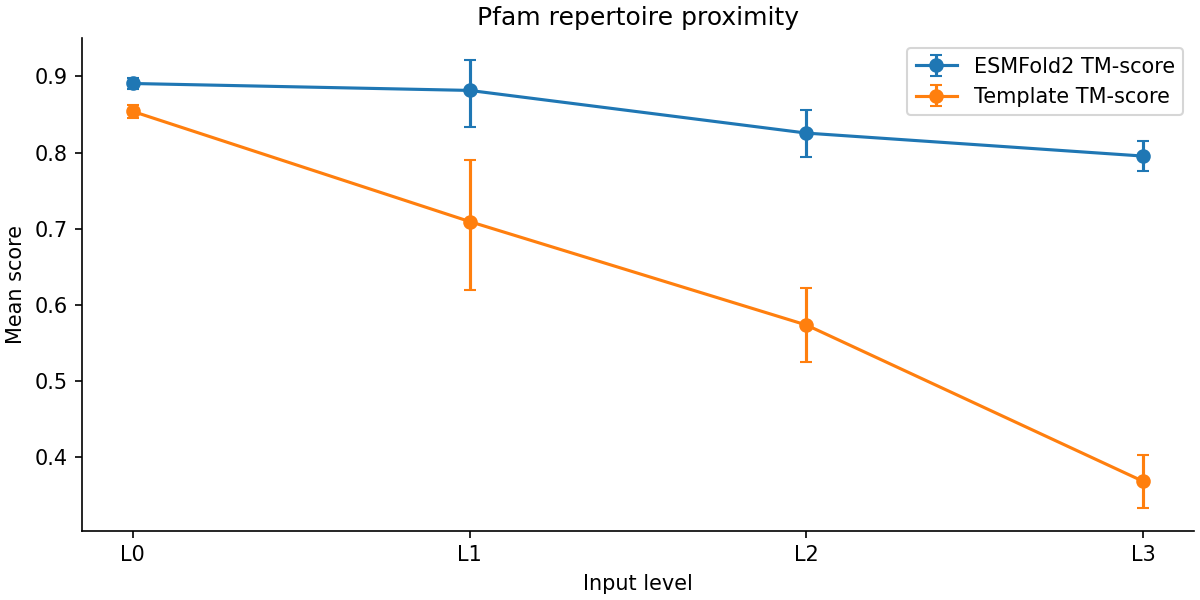

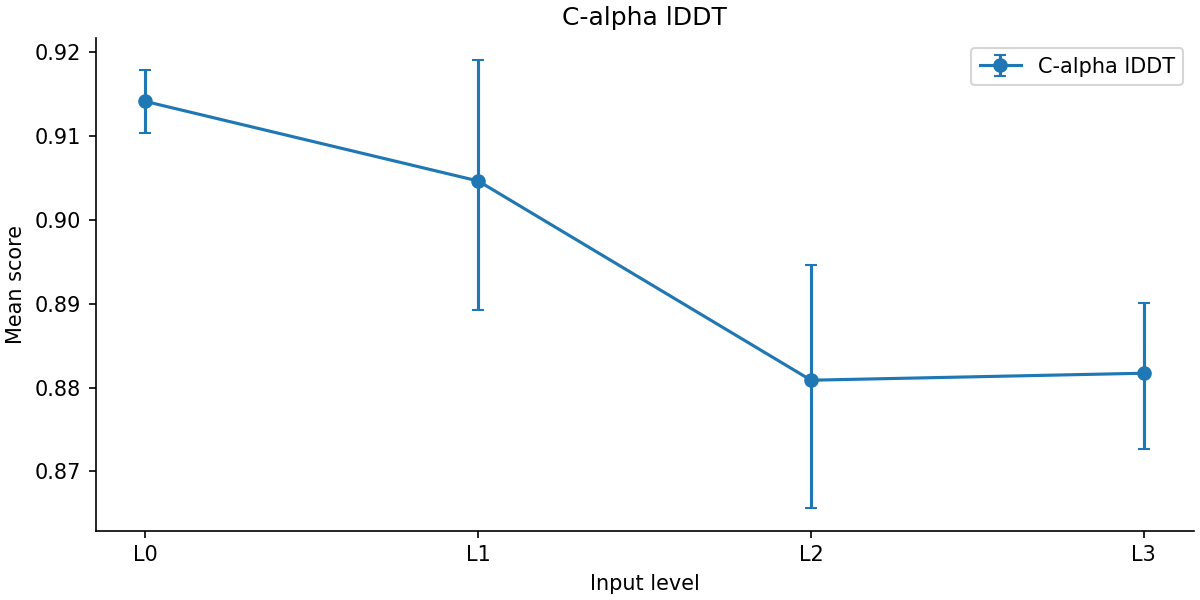

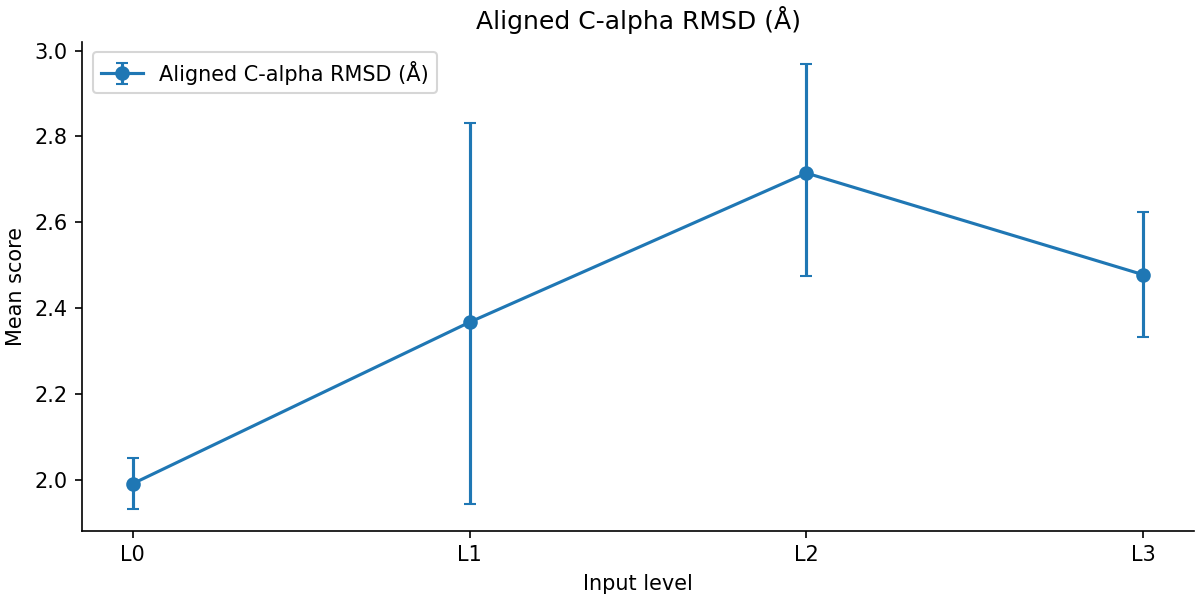

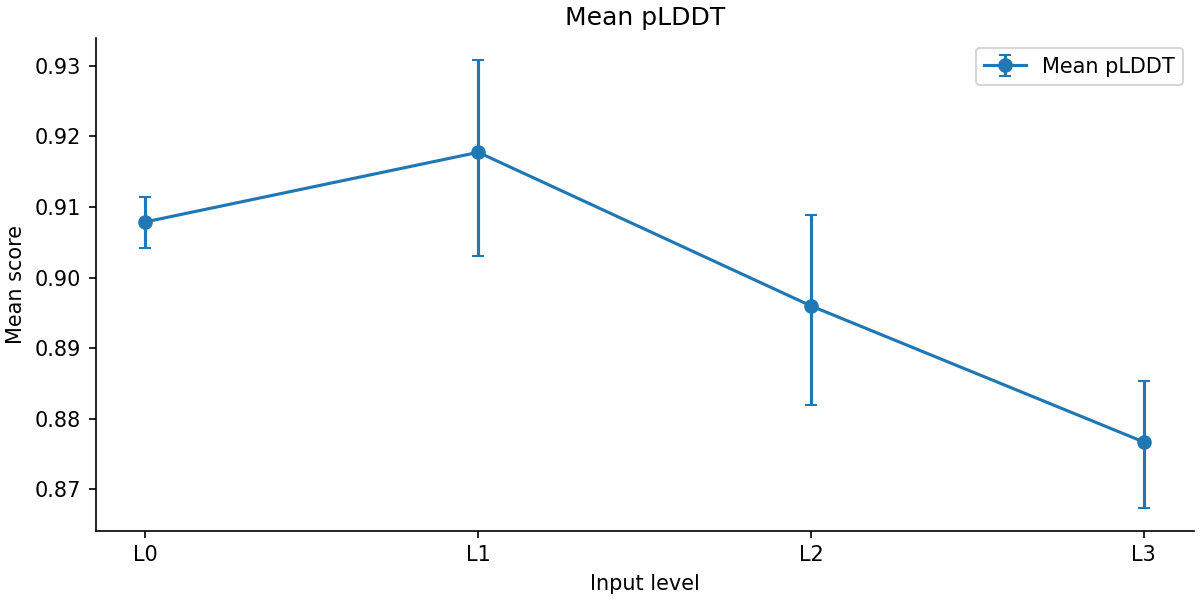

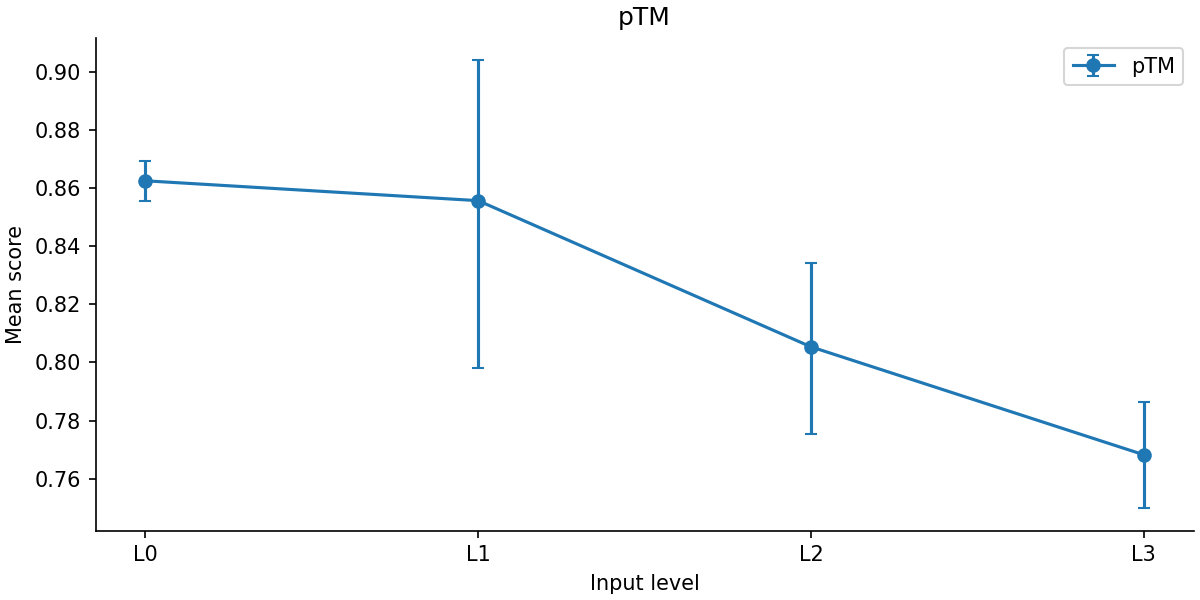

status                        calculated
n0                                  1517
n3                                   322
model_drop                       0.09531
model_lo                        0.074223
model_hi                        0.116744
reference_drop                  0.485761
reference_lo                    0.449884
reference_hi                    0.521491
model_minus_reference_drop     -0.390451
difference_lo                  -0.430787
difference_hi                  -0.350747
dtype: object

,term,coefficient,hc3_se,p_two_sided,lo,hi,n,design_columns,design_rank,status
0,Intercept,3.695207e-01,2.997154e-02,6.318551e-35,3.107776e-01,4.282638e-01,1987,27,24,calculated
1,C(method)[T.Xray],2.834487e-02,7.690525e-03,2.280866e-04,1.327172e-02,4.341802e-02,1987,27,24,calculated
2,C(taxonomy)[T.Bacteria],-5.587892e-03,1.965969e-02,7.762334e-01,-4.412017e-02,3.294439e-02,1987,27,24,calculated
3,C(taxonomy)[T.Bacteria;Eukaryota],-1.648030e-01,7.063706e-02,1.964314e-02,-3.032491e-01,-2.635691e-02,1987,27,24,calculated
4,C(taxonomy)[T.Eukaryota],-2.757178e-03,1.964018e-02,8.883561e-01,-4.125123e-02,3.573687e-02,1987,27,24,calculated
5,C(taxonomy)[T.Eukaryota;Viruses],-1.731864e-01,1.135957e-01,1.273624e-01,-3.958298e-01,4.945708e-02,1987,27,24,calculated
6,C(taxonomy)[T.Viruses],-1.565901e-01,4.058983e-02,1.143820e-04,-2.361447e-01,-7.703547e-02,1987,27,24,calculated
7,C(taxonomy)[T.unknown],8.360417e-02,2.545553e-02,1.022278e-03,3.371225e-02,1.334961e-01,1987,27,24,calculated
8,assembly_annotated[T.True],3.695207e-01,2.997154e-02,6.318551e-35,3.107776e-01,4.282638e-01,1987,27,24,calculated
9,similarity,7.817840e-02,1.823363e-02,1.806183e-05,4.244115e-02,1.139157e-01,1987,27,24,calculated


,term,coefficient,hc3_se,p_two_sided,lo,hi,n,design_columns,design_rank,status
0,Intercept,3.799118e-01,3.036984e-02,6.623170e-36,3.203880e-01,4.394356e-01,1839,27,24,calculated
1,C(method)[T.Xray],3.608232e-02,7.993774e-03,6.367553e-06,2.041481e-02,5.174983e-02,1839,27,24,calculated
2,C(taxonomy)[T.Bacteria],1.624927e-03,2.125852e-02,9.390718e-01,-4.004100e-02,4.329086e-02,1839,27,24,calculated
3,C(taxonomy)[T.Bacteria;Eukaryota],-1.534197e-01,7.089830e-02,3.046892e-02,-2.923778e-01,-1.446158e-02,1839,27,24,calculated
4,C(taxonomy)[T.Eukaryota],5.311909e-03,2.122151e-02,8.023493e-01,-3.628148e-02,4.690530e-02,1839,27,24,calculated
5,C(taxonomy)[T.Eukaryota;Viruses],-1.202670e-01,1.299658e-01,3.547712e-01,-3.749954e-01,1.344613e-01,1839,27,24,calculated
6,C(taxonomy)[T.Viruses],-1.705598e-01,4.606765e-02,2.135887e-04,-2.608508e-01,-8.026889e-02,1839,27,24,calculated
7,C(taxonomy)[T.unknown],9.426693e-02,2.713163e-02,5.119419e-04,4.108991e-02,1.474440e-01,1839,27,24,calculated
8,assembly_annotated[T.True],3.799118e-01,3.036984e-02,6.623170e-36,3.203880e-01,4.394356e-01,1839,27,24,calculated
9,high_similarity,7.292479e-02,1.538342e-02,2.132117e-06,4.277385e-02,1.030757e-01,1839,27,24,calculated


,term,coefficient,hc3_se,p_two_sided,lo,hi,n,design_columns,design_rank,status,control,fraction_removed,invalidating
0,high_similarity,0.093793,1.078365e-02,3.386582e-18,0.072657,0.114929,1839,6,5,calculated,length,0.015920,False
1,high_similarity,0.072551,1.595952e-02,5.469633e-06,0.041271,0.103831,1839,5,5,calculated,homology,0.238795,False
2,high_similarity,0.094927,1.080610e-02,1.569136e-18,0.073748,0.116107,1839,3,3,calculated,release_date,0.004019,False
3,high_similarity,0.089125,1.049235e-02,1.992147e-17,0.068560,0.109689,1839,3,3,calculated,method,0.064900,False
4,high_similarity,0.076076,1.065886e-02,9.514666e-13,0.055185,0.096967,1839,3,3,calculated,resolution,0.201807,False
5,high_similarity,0.090332,1.086991e-02,9.544032e-17,0.069028,0.111637,1839,3,3,calculated,coordinate_coverage,0.052228,False
6,high_similarity,0.089381,1.075187e-02,9.325354e-17,0.068308,0.110454,1839,5,4,calculated,pfam_count_coverage,0.062210,False
7,high_similarity,0.091649,1.081258e-02,2.328195e-17,0.070456,0.112841,1839,8,8,calculated,taxonomy,0.038417,False
8,high_similarity,0.094900,1.079766e-02,1.509650e-18,0.073737,0.116063,1839,3,3,calculated,low_complexity,0.004304,False
9,high_similarity,0.091047,1.074103e-02,2.320332e-17,0.069995,0.112099,1839,3,3,calculated,disorder,0.044736,False


,status,n0,n3,model_drop,model_lo,model_hi,reference_drop,reference_lo,reference_hi,model_minus_reference_drop,difference_lo,difference_hi,sensitivity,n
0,calculated,1379,274,0.098021,0.075403,0.120815,0.483674,0.445948,0.522498,-0.385653,-0.428369,-0.344236,coverage_ge80,1782
1,calculated,314,81,0.037316,0.006381,0.069835,0.455217,0.383983,0.524992,-0.417901,-0.494954,-0.341764,monomeric_annotated,428
2,calculated,1510,227,0.097775,0.072743,0.123600,0.335618,0.302147,0.370080,-0.237843,-0.276770,-0.200015,complete_reference,1877


,term,coefficient,hc3_se,p_two_sided,lo,hi,n,design_columns,design_rank,status,sensitivity
0,Intercept,3.390246e-01,3.960246e-02,1.121904e-17,2.614052e-01,4.166440e-01,1782,27,24,calculated,coverage_ge80
1,C(method)[T.Xray],3.314775e-02,7.951352e-03,3.061814e-05,1.756339e-02,4.873212e-02,1782,27,24,calculated,coverage_ge80
2,C(taxonomy)[T.Bacteria],-3.677109e-03,1.975363e-02,8.523283e-01,-4.239352e-02,3.503930e-02,1782,27,24,calculated,coverage_ge80
3,C(taxonomy)[T.Bacteria;Eukaryota],-1.882137e-01,8.544777e-02,2.761766e-02,-3.556882e-01,-2.073912e-02,1782,27,24,calculated,coverage_ge80
4,C(taxonomy)[T.Eukaryota],-4.278238e-03,1.972040e-02,8.282514e-01,-4.292951e-02,3.437304e-02,1782,27,24,calculated,coverage_ge80
...,...,...,...,...,...,...,...,...,...,...,...
75,pfam_coverage_missing,4.539994e-19,1.918455e-18,8.129295e-01,-3.306102e-18,4.214101e-18,1877,27,23,calculated,complete_reference
76,low_complexity_fraction,2.681255e-02,3.637051e-02,4.609972e-01,-4.447234e-02,9.809743e-02,1877,27,23,calculated,complete_reference
77,disorder_fraction,-1.876164e-01,5.771334e-02,1.150680e-03,-3.007324e-01,-7.450028e-02,1877,27,23,calculated,complete_reference
78,coiled_coil_fraction,-5.491231e-01,1.072311e-01,3.040331e-07,-7.592923e-01,-3.389540e-01,1877,27,23,calculated,complete_reference


,median_similarity
level,
L0,1.000000
L1,0.750000
L2,0.666667
L3,0.267857


,level,mean,isotonic_decreasing_fit
0,L0,0.890654,0.890654
1,L1,0.881559,0.881559
2,L2,0.825530,0.825530
3,L3,0.795343,0.795343


In [16]:
display(curves);plot_curve(curves,'Pfam repertoire proximity')
for metric in ['ca_lddt','rmsd','mean_plddt','ptm']:
    plot_curve(curves,curve_plot_labels[metric],(metric,))
display(pd.Series(contrast));display(full_fit);display(extreme_fit)
display(single_controls);display(sensitivities);display(sensitivity_fits)
display(axis_order.to_frame('median_similarity'));display(trend)


## 6. Decision and explanation

Use the calculated effect sizes, uncertainty, adjusted coefficients and controls below. A result applies to the actual selected input population and model implementation; it does not establish performance outside this cohort.


In [17]:
adjusted=full_fit[full_fit.term.eq('similarity')].iloc[0]
ordered=bool((np.diff(axis_order.dropna())<0).all())
real_decline=bool(contrast.get('model_lo',-1)>0)
adjusted_decline=bool(adjusted.get('lo',-1)>0)
invalidated=bool(single_controls.invalidating.any())
if ordered and real_decline and adjusted_decline and not invalidated:
    decision='Accept lower Pfam repertoire proximity as a declining-accuracy regime in this evaluated population: the paired extreme interval and adjusted similarity coefficient are positive.'
else:
    decision='Do not accept a general Pfam-proximity decline from these data: at least one of level ordering, extreme uncertainty, adjusted attribution, or single-control robustness is unresolved.'
if contrast.get('difference_hi',1)<0:
    reference_interpretation='The template reference loses more accuracy across the extremes; this is shared difficulty rather than excess model-specific degradation.'
elif contrast.get('difference_lo',-1)>0:
    reference_interpretation='ESMFold2 loses more accuracy than the same-target template reference.'
else:reference_interpretation='The relative degradation of model and template reference is unresolved.'
print(reference_interpretation)

print(decision)
print('Evaluated chains:',len(measurements),'primary-axis chains:',len(primary),'auxiliary controls:',int(measurements.level.eq('CONTROL').sum()))
output=ROOT/ANALYSIS_ID.split('/')[-1];output.mkdir(exist_ok=True)
features.to_csv(output/'axis_levels.csv',index=False)
measurements.to_csv(output/'scores.csv',index=False)
for name,table in analysis_outputs.items():table.to_csv(output/(name+'.csv'),index=False)
(output/'extreme_contrast.json').write_text(json.dumps(contrast,indent=2))
record={'analysis_id':ANALYSIS_ID,'completed':True,'host':socket.gethostname(),
        'source_snapshots':source_receipts,'panel_sha256':sha256_file(ROOT/'panel.csv'),
        'n_evaluated':len(measurements),'n_primary':len(primary),
        'model_checkpoint':checkpoint_signature,'model_settings':settings,
        'new_inference_targets':inferred_target_count,'verified_prediction_targets':len(measurements),
        'software_controls':control_setup_receipt,'decision':decision,
        'bootstrap_replicates':BOOTSTRAPS,'bootstrap_seed':SEED,
        'outputs':{p.name:sha256_file(p) for p in output.glob('*') if p.is_file() and p.name!='CALCULATION_RECEIPT.json'}}
(output/'CALCULATION_RECEIPT.json').write_text(json.dumps(record,indent=2))


The template reference loses more accuracy across the extremes; this is shared difficulty rather than excess model-specific degradation.
Accept lower Pfam repertoire proximity as a declining-accuracy regime in this evaluated population: the paired extreme interval and adjusted similarity coefficient are positive.
Evaluated chains: 2517 primary-axis chains: 1987 auxiliary controls: 530


6588